In [1]:
!pip install pandas
!pip install matplotlib


=== Data Summary ===
  workload_label    experiment  hit_rate_apc  hit_rate_solidarity  \
0              1    workload_1     91.360947            91.360947   
1              2    workload_2     77.813309            73.633318   
2              3    workload_3     65.181324            56.416092   
3              4    workload_4     77.383231            74.746616   
4              5    workload_5     72.288676            70.255183   
5            Avg  workload_avg     82.669737            81.117219   

   hit_rate_isolation  hit_rate_safekv  
0           91.360947        91.360947  
1           61.197541        61.397899  
2           33.228611        33.387168  
3            7.162418         7.229428  
4            0.525701         0.059809  
5           42.432312        42.608825  



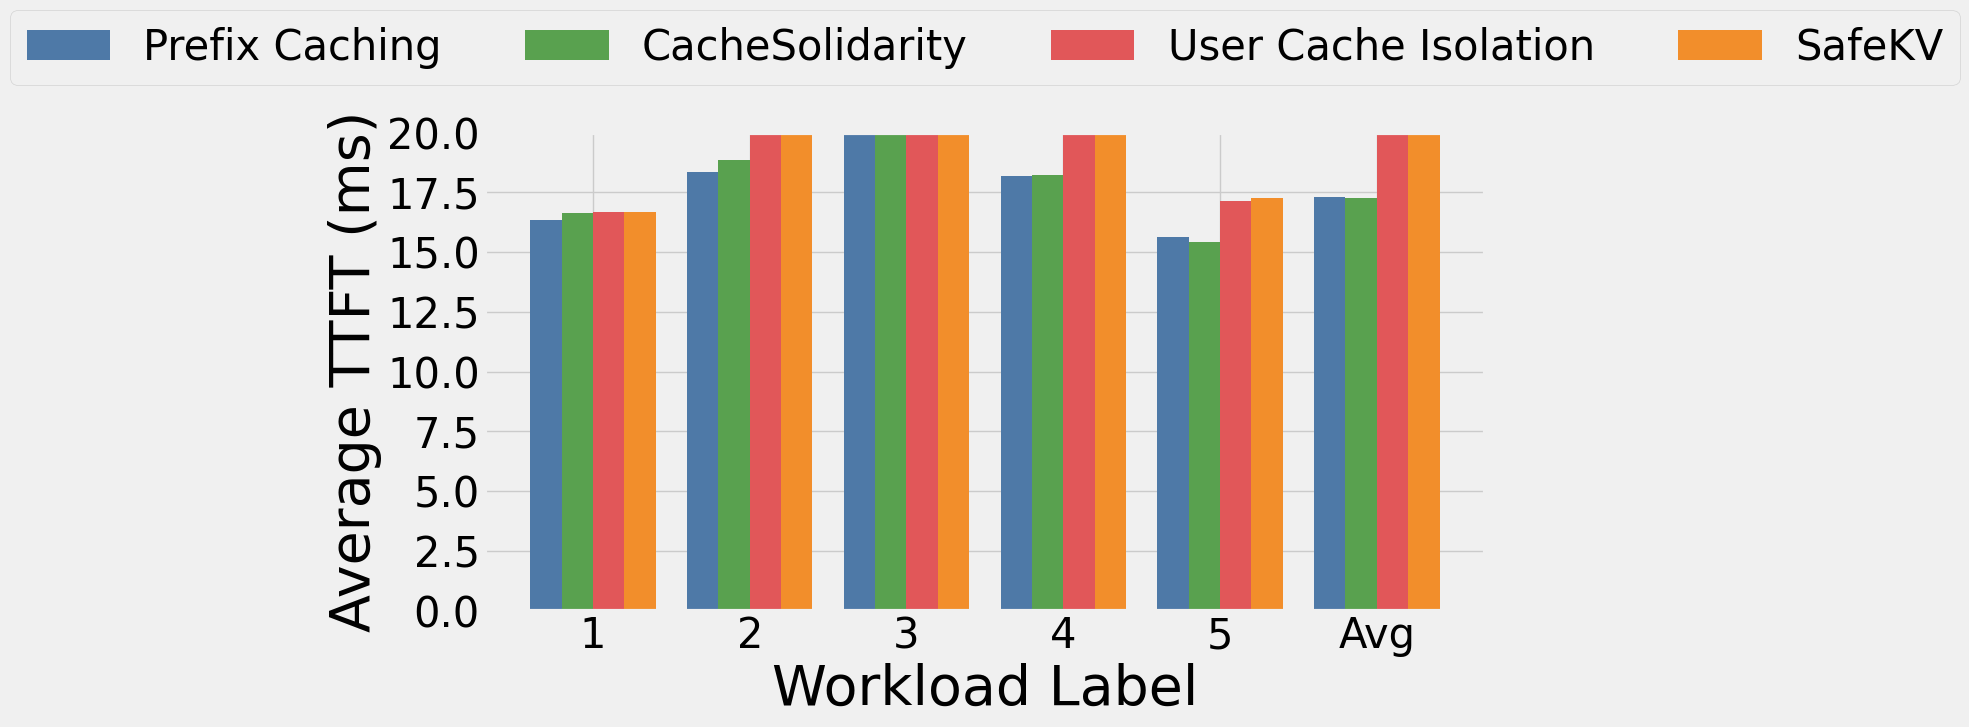

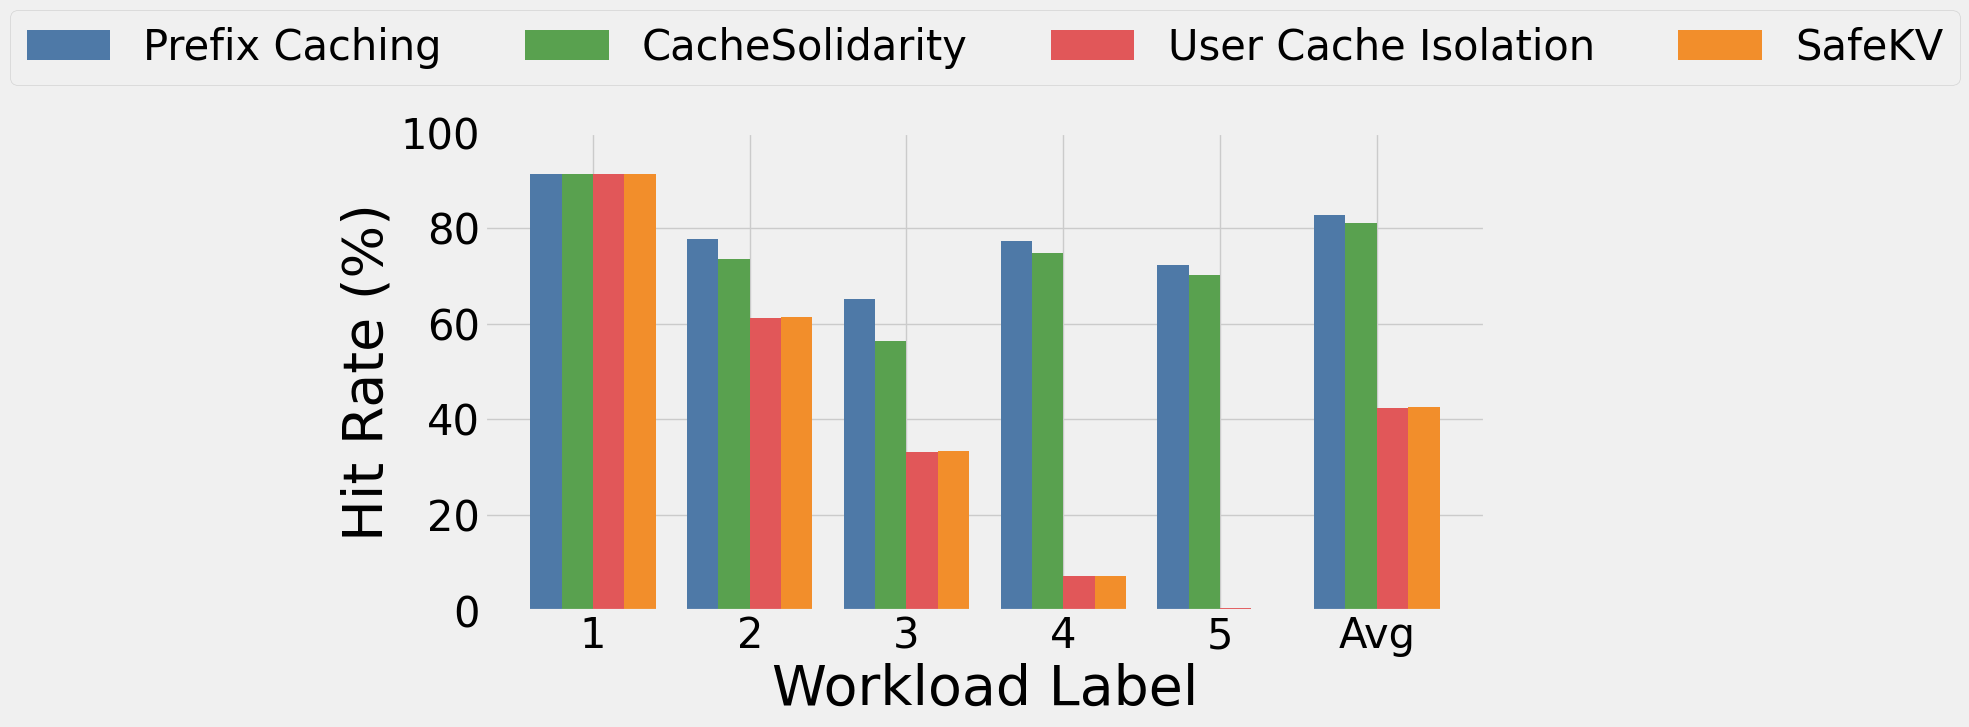

✅ Saved plots to:
  ./plots/ttft_raw.pdf
  ./plots/hit_rate_raw.pdf


In [10]:
import os
import re
import glob
import json
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# Configuration
# ============================================================

TARGET_RATE = 10.0
BASE = "./temp_results/fig7_workloads/Llama-2-13b-chat-hf"
OUTPUT_DIR = "./plots"

# Mode folder name -> display label / color / dataframe column suffix
MODES = {
    "APC":            {"label": "Prefix Caching",     "color": "#4E79A7", "suffix": "apc"},
    "CacheSolidarity": {"label": "CacheSolidarity",     "color": "#59A14F", "suffix": "solidarity"},
    "Isolation":      {"label": "User Cache Isolation","color": "#E15759", "suffix": "isolation"},
    "SafeKV":         {"label": "SafeKV",              "color": "#F28E2B", "suffix": "safekv"},
}

# --- Plot Style Configuration ---
PLOT_CONFIG = {
    "fontsize": 40,        # all text sizes
    "labelsize": 40,       # axis label size
    "ticksize": 30,        # tick label size
    "legendsize": 30,      # legend text size
    "bar_width": 0.2,      # width of each bar (narrower to fit 4 bars/group)
    "figsize": (16, 8),    # (width, height) of each figure
}

os.makedirs(OUTPUT_DIR, exist_ok=True)
plt.style.use("fivethirtyeight")

# ============================================================
# Utilities
# ============================================================

def read_jsonl(path):
    """Read a JSONL file into a list of dicts."""
    if not path or not os.path.exists(path):
        return []
    try:
        with open(path, "r", encoding="utf-8") as f:
            return [json.loads(line) for line in f if line.strip()]
    except (UnicodeDecodeError, json.JSONDecodeError) as e:
        print(f"⚠️ Skipping unreadable file {path}: {e}")
        return []


def process_mode(rate_dir, exp_name, mode):
    """Compute hit rate and average TTFT for one mode (APC, CacheSolidarity, Isolation, SafeKV)."""
    mode_dir = os.path.join(rate_dir, mode)
    if not os.path.isdir(mode_dir):
        return None, None

    block_files = glob.glob(os.path.join(mode_dir, "block_*.jsonl"))
    masked_files = glob.glob(os.path.join(mode_dir, f"{exp_name}.jsonl"))

    block_file = block_files[0] if block_files else None
    masked_file = masked_files[0] if masked_files else None

    block_data = read_jsonl(block_file)
    masked_data = read_jsonl(masked_file)

    # Hit rate
    hits = sum(1 for r in block_data if r.get("event") == "hit")
    total = len(block_data)
    hit_rate = hits / total if total > 0 else None

    # Average TTFT
    ttfts = [r["ttft"] for r in masked_data if "ttft" in r]
    avg_ttft = sum(ttfts) / len(ttfts) if ttfts else None

    return hit_rate, avg_ttft


# ============================================================
# Collect results
# ============================================================

# workload_1, workload_2, ..., workload_avg
pattern = re.compile(r"(workload_.*)")
rows = []

for exp_dir in sorted(glob.glob(f"{BASE}/workload_*", recursive=False)):
    exp_name = os.path.basename(exp_dir)
    if not pattern.match(exp_name):
        continue

    # Rate dir has no trailing underscore in this layout: "Rate_10.0"
    rate_dir = os.path.join(exp_dir, f"Rate_{TARGET_RATE}")
    if not os.path.isdir(rate_dir):
        print(f"[WARN] {exp_name} does NOT have Rate_{TARGET_RATE} — skipping")
        continue

    row = {"experiment": exp_name, "rate": TARGET_RATE}
    for mode_dir_name, meta in MODES.items():
        hit, ttft = process_mode(rate_dir, exp_name, mode_dir_name)
        row[f"hit_rate_{meta['suffix']}"] = hit
        row[f"ttft_{meta['suffix']}"] = ttft
    rows.append(row)

# ============================================================
# DataFrame setup
# ============================================================

df = pd.DataFrame(rows)

# Convert hit rates to percentages and TTFT to ms
for meta in MODES.values():
    suf = meta["suffix"]
    df[f"hit_rate_{suf}"] = df[f"hit_rate_{suf}"] * 100
    df[f"ttft_{suf}"] = df[f"ttft_{suf}"] * 1000

# Assign workload labels
df["workload_label"] = df.index + 1
df["workload_label"] = df["workload_label"].astype(object)

# Sort workloads by hit_rate_isolation (descending)
df = df.sort_values(by="hit_rate_isolation", ascending=False).reset_index(drop=True)

# Rename 'workload_avg' to 'Avg' and move to end
df.loc[df["experiment"] == "workload_avg", "workload_label"] = "Avg"
avg_row = df[df["experiment"] == "workload_avg"]
df = pd.concat([df[df["experiment"] != "workload_avg"], avg_row], ignore_index=True)

# --- Print summary ---
print("\n=== Data Summary ===")
print(df[["workload_label", "experiment"] + [f"hit_rate_{m['suffix']}" for m in MODES.values()]])
print("====================\n")

# ============================================================
# Shared bar-offset helper (centers N bars per group)
# ============================================================

n_modes = len(MODES)
bar_width = PLOT_CONFIG["bar_width"]
offsets = [(-((n_modes - 1) / 2) + i) * bar_width for i in range(n_modes)]
x = range(len(df))

xticks_labels = [str(i) for i in range(1, len(df) + 1)]
xticks_labels[-1] = "Avg"

# ============================================================
# PLOT 1: Average TTFT (non-normalized)
# ============================================================

plt.figure(figsize=PLOT_CONFIG["figsize"])

for offset, (mode_dir_name, meta) in zip(offsets, MODES.items()):
    plt.bar([xi + offset for xi in x], df[f"ttft_{meta['suffix']}"], width=bar_width,
            label=meta["label"], color=meta["color"])

plt.xticks(range(len(df)), xticks_labels, fontsize=PLOT_CONFIG["ticksize"])
plt.yticks(fontsize=PLOT_CONFIG["ticksize"])
plt.ylim(0, 20)
plt.ylabel("Average TTFT (ms)", fontsize=PLOT_CONFIG["labelsize"])
plt.xlabel("Workload Label", fontsize=PLOT_CONFIG["labelsize"])
plt.legend(fontsize=PLOT_CONFIG["legendsize"], ncol=n_modes, loc="upper center", bbox_to_anchor=(0.5, 1.3))
plt.tight_layout()

ttft_plot_path = os.path.join(OUTPUT_DIR, "ttft_raw.pdf")
plt.savefig(ttft_plot_path, bbox_inches="tight", transparent=True)
plt.show()

# ============================================================
# PLOT 2: Hit Rate
# ============================================================

plt.figure(figsize=PLOT_CONFIG["figsize"])

for offset, (mode_dir_name, meta) in zip(offsets, MODES.items()):
    plt.bar([xi + offset for xi in x], df[f"hit_rate_{meta['suffix']}"], width=bar_width,
            label=meta["label"], color=meta["color"])

plt.xticks(range(len(df)), xticks_labels, fontsize=PLOT_CONFIG["ticksize"])
plt.yticks(fontsize=PLOT_CONFIG["ticksize"])
plt.ylim(0, 100)
plt.ylabel("Hit Rate (%)", fontsize=PLOT_CONFIG["labelsize"])
plt.xlabel("Workload Label", fontsize=PLOT_CONFIG["labelsize"])
plt.legend(fontsize=PLOT_CONFIG["legendsize"], ncol=n_modes, loc="upper center", bbox_to_anchor=(0.5, 1.3))
plt.tight_layout()

hit_rate_plot_path = os.path.join(OUTPUT_DIR, "hit_rate_raw.pdf")
plt.savefig(hit_rate_plot_path, bbox_inches="tight", transparent=True)
plt.show()

print(f"✅ Saved plots to:\n  {ttft_plot_path}\n  {hit_rate_plot_path}")


=== Data Summary ===
  model_label                            model  hit_rate_apc  hit_rate_solidarity  hit_rate_isolation  hit_rate_safekv
Qwen2.5-VL 3B           Qwen2.5-VL-3B-Instruct     81.925914            80.318223           43.465322        43.573382
   LLaVA 0.5B llava-onevision-qwen2-0.5b-ov-hf     81.925914            80.318223           43.465322        43.573382
   Gemma 3 4B                    gemma-3-4b-it     81.969759            80.433183           42.876947        42.975072
  Llama-2 13B              Llama-2-13b-chat-hf     82.669737            81.117219           42.432312        42.608825
   Llama-2 7B               Llama-2-7b-chat-hf     82.669737            81.117219           42.432312        42.608825



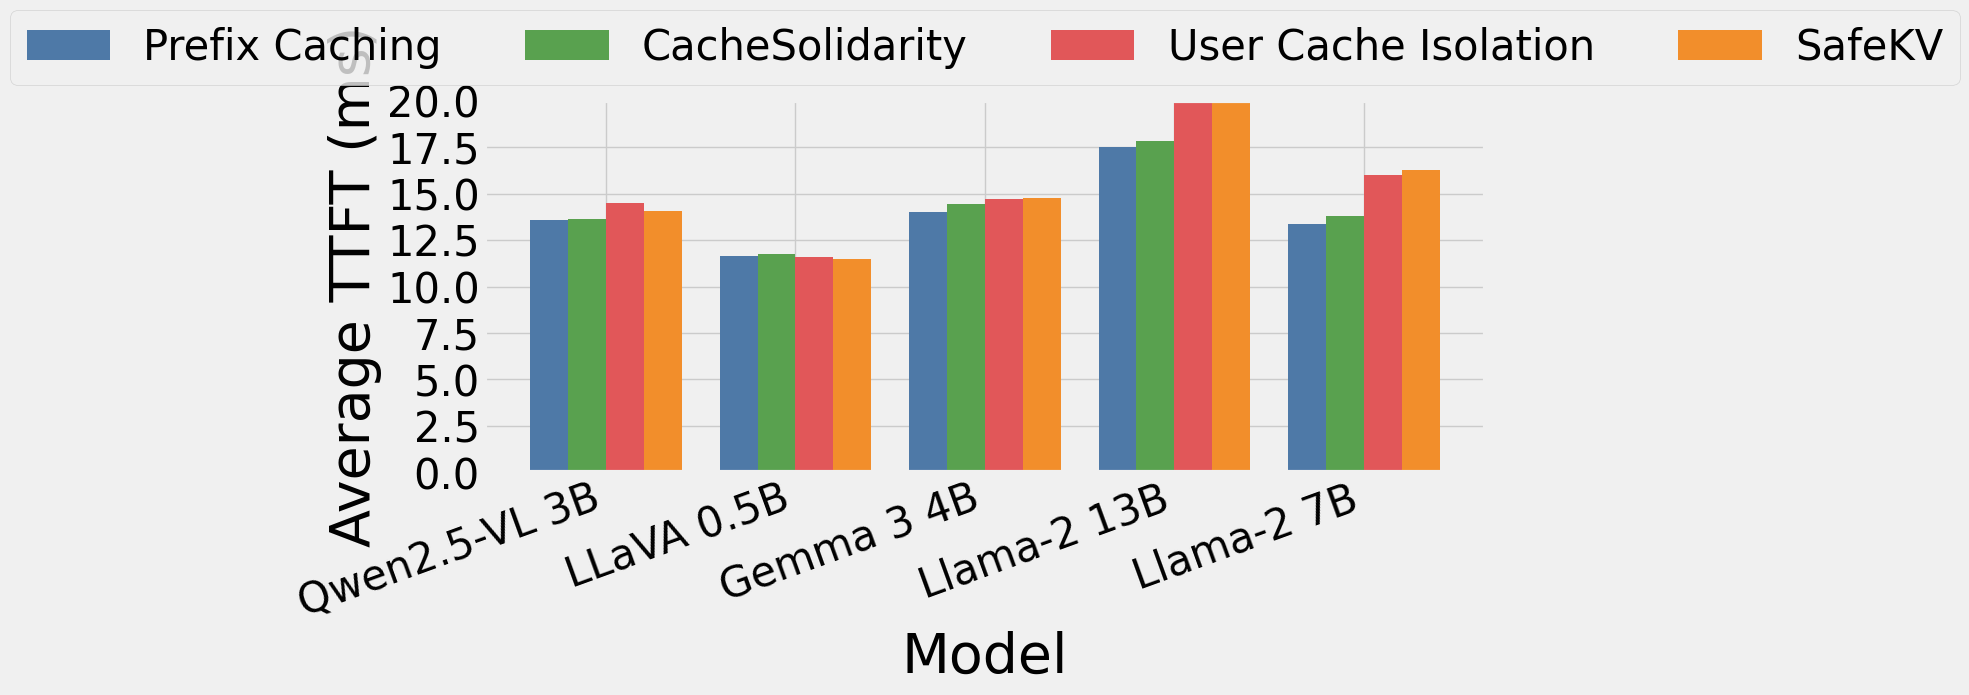

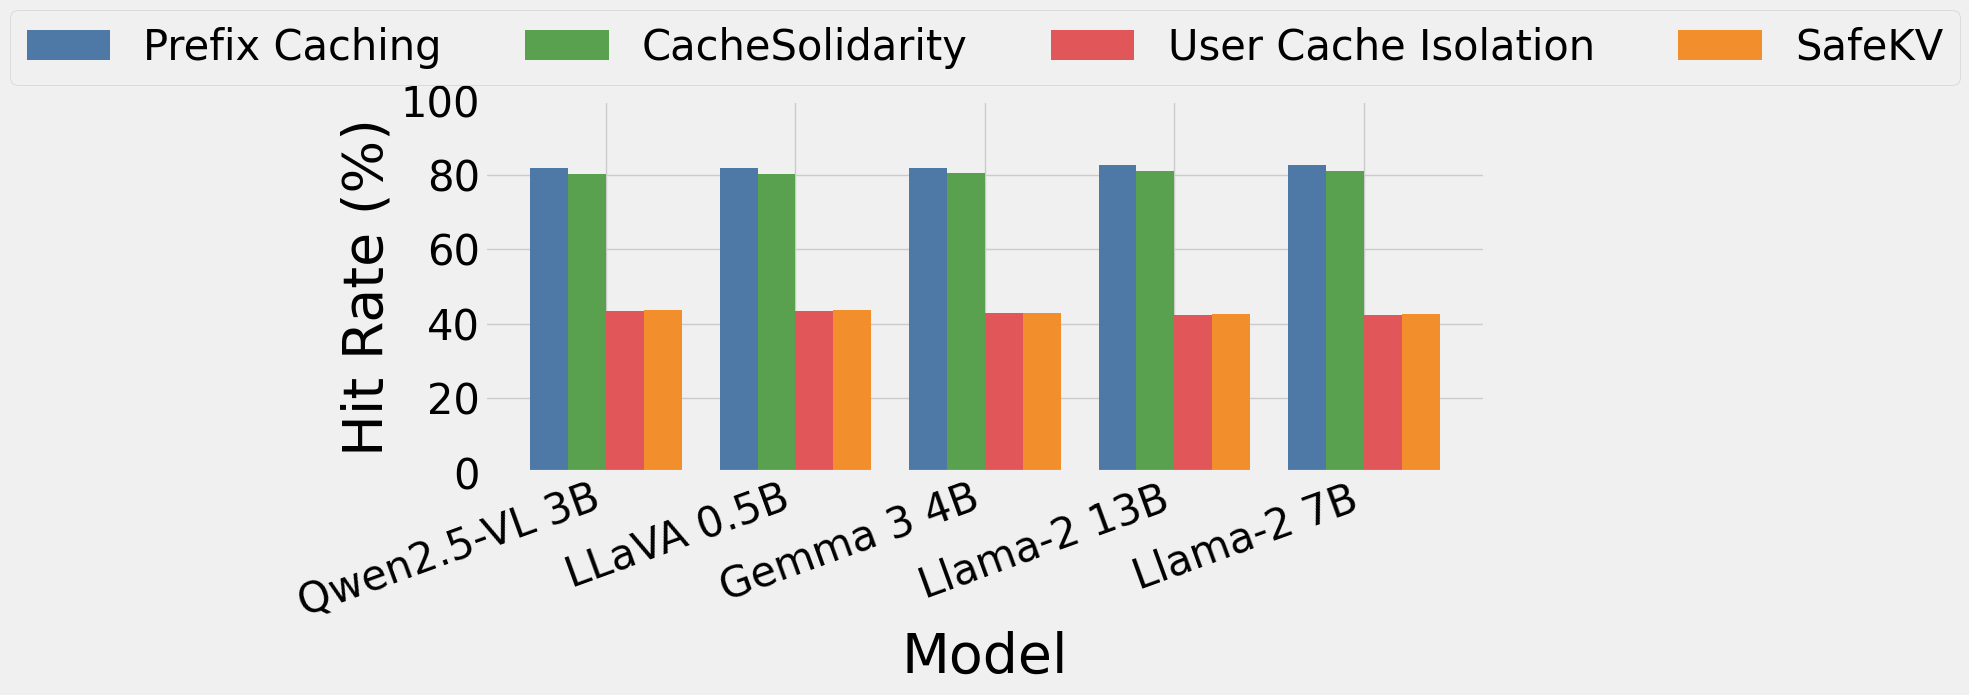

✅ Saved plots to:
  ./plots_models/ttft_models.pdf
  ./plots_models/hit_rate_models.pdf


In [12]:
import os
import glob
import json
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# Configuration
# ============================================================

TARGET_RATE = 10.0

BASE = "./temp_results/fig8_models"
OUTPUT_DIR = "./plots_models"

# workload to use inside every model
WORKLOAD = "workload_avg"

MODES = {
    "APC": {
        "label": "Prefix Caching",
        "color": "#4E79A7",
        "suffix": "apc",
    },
    "CacheSolidarity": {
        "label": "CacheSolidarity",
        "color": "#59A14F",
        "suffix": "solidarity",
    },
    "Isolation": {
        "label": "User Cache Isolation",
        "color": "#E15759",
        "suffix": "isolation",
    },
    "SafeKV": {
        "label": "SafeKV",
        "color": "#F28E2B",
        "suffix": "safekv",
    },
}

# Display names for models
MODEL_LABELS = {
    "gemma-3-4b-it": "Gemma 3 4B",
    "Llama-2-7b-chat-hf": "Llama-2 7B",
    "Llama-2-13b-chat-hf": "Llama-2 13B",
    "llava-onevision-qwen2-0.5b-ov-hf": "LLaVA 0.5B",
    "Qwen2.5-VL-3B-Instruct": "Qwen2.5-VL 3B",
}

# --- Plot Style Configuration ---
PLOT_CONFIG = {
    "fontsize": 40,
    "labelsize": 40,
    "ticksize": 30,
    "legendsize": 30,
    "bar_width": 0.2,
    "figsize": (16, 8),
}

os.makedirs(OUTPUT_DIR, exist_ok=True)

plt.style.use("fivethirtyeight")


# ============================================================
# Utilities
# ============================================================

def read_jsonl(path):
    """Read a JSONL file into a list of dicts."""
    if not path or not os.path.exists(path):
        return []

    try:
        with open(path, "r", encoding="utf-8") as f:
            return [
                json.loads(line)
                for line in f
                if line.strip()
            ]
    except (UnicodeDecodeError, json.JSONDecodeError) as e:
        print(f"⚠️ Skipping unreadable file {path}: {e}")
        return []


def process_mode(rate_dir, workload, mode):
    """
    Compute hit rate and average TTFT for one mode
    for the specified workload.
    """

    mode_dir = os.path.join(rate_dir, mode)

    if not os.path.isdir(mode_dir):
        return None, None

    # Find block file
    block_files = glob.glob(
        os.path.join(mode_dir, "block_*.jsonl")
    )

    # Find workload JSONL
    workload_files = glob.glob(
        os.path.join(mode_dir, f"{workload}.jsonl")
    )

    block_file = block_files[0] if block_files else None
    workload_file = workload_files[0] if workload_files else None

    block_data = read_jsonl(block_file)
    workload_data = read_jsonl(workload_file)

    # --------------------------------------------------------
    # Hit rate
    # --------------------------------------------------------

    hits = sum(
        1
        for r in block_data
        if r.get("event") == "hit"
    )

    total = len(block_data)

    hit_rate = hits / total if total > 0 else None

    # --------------------------------------------------------
    # Average TTFT
    # --------------------------------------------------------

    ttfts = [
        r["ttft"]
        for r in workload_data
        if "ttft" in r
    ]

    avg_ttft = (
        sum(ttfts) / len(ttfts)
        if ttfts
        else None
    )

    return hit_rate, avg_ttft


# ============================================================
# Collect results
# ============================================================

rows = []

# Every directory directly under BASE is a model
model_dirs = sorted(
    [
        d
        for d in glob.glob(os.path.join(BASE, "*"))
        if os.path.isdir(d)
    ]
)

for model_dir in model_dirs:

    model_name = os.path.basename(model_dir)

    rate_dir = os.path.join(
        model_dir,
        WORKLOAD,
        f"Rate_{TARGET_RATE}"
    )

    if not os.path.isdir(rate_dir):
        print(
            f"[WARN] {model_name} does NOT have "
            f"{WORKLOAD}/Rate_{TARGET_RATE} — skipping"
        )
        continue

    row = {
        "model": model_name,
    }

    for mode_dir_name, meta in MODES.items():

        hit, ttft = process_mode(
            rate_dir,
            WORKLOAD,
            mode_dir_name
        )

        row[f"hit_rate_{meta['suffix']}"] = hit
        row[f"ttft_{meta['suffix']}"] = ttft

    rows.append(row)


# ============================================================
# DataFrame setup
# ============================================================

df = pd.DataFrame(rows)

if df.empty:
    raise RuntimeError(
        "No model results were found."
    )

# Convert hit rates to percentages
# and TTFT to milliseconds
for meta in MODES.values():

    suf = meta["suffix"]

    df[f"hit_rate_{suf}"] *= 100
    df[f"ttft_{suf}"] *= 1000


# Display labels
df["model_label"] = df["model"].map(
    lambda x: MODEL_LABELS.get(x, x)
)


# ============================================================
# Optional sorting
# ============================================================

# Sort models by Isolation hit rate, descending.
#
# If you prefer alphabetical/model-size order,
# simply remove this sort.

df = df.sort_values(
    by="hit_rate_isolation",
    ascending=False
).reset_index(drop=True)


# ============================================================
# Print summary
# ============================================================

print("\n=== Data Summary ===")

summary_columns = [
    "model_label",
    "model",
]

summary_columns += [
    f"hit_rate_{m['suffix']}"
    for m in MODES.values()
]

print(df[summary_columns].to_string(index=False))

print("====================\n")


# ============================================================
# Shared bar-offset helper
# ============================================================

n_modes = len(MODES)

bar_width = PLOT_CONFIG["bar_width"]

offsets = [
    (-((n_modes - 1) / 2) + i) * bar_width
    for i in range(n_modes)
]

x = range(len(df))

xticks_labels = df["model_label"].tolist()


# ============================================================
# PLOT 1: Average TTFT
# ============================================================

plt.figure(
    figsize=PLOT_CONFIG["figsize"]
)

for offset, (mode_dir_name, meta) in zip(
    offsets,
    MODES.items()
):

    plt.bar(
        [xi + offset for xi in x],
        df[f"ttft_{meta['suffix']}"],
        width=bar_width,
        label=meta["label"],
        color=meta["color"],
    )


plt.xticks(
    range(len(df)),
    xticks_labels,
    fontsize=PLOT_CONFIG["ticksize"],
    rotation=20,
    ha="right",
)

plt.yticks(
    fontsize=PLOT_CONFIG["ticksize"]
)

plt.ylim(0, 20)

plt.ylabel(
    "Average TTFT (ms)",
    fontsize=PLOT_CONFIG["labelsize"]
)

plt.xlabel(
    "Model",
    fontsize=PLOT_CONFIG["labelsize"]
)

plt.legend(
    fontsize=PLOT_CONFIG["legendsize"],
    ncol=n_modes,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.3),
)

plt.tight_layout()

ttft_plot_path = os.path.join(
    OUTPUT_DIR,
    "ttft_models.pdf"
)

plt.savefig(
    ttft_plot_path,
    bbox_inches="tight",
    transparent=True,
)

plt.show()


# ============================================================
# PLOT 2: Hit Rate
# ============================================================

plt.figure(
    figsize=PLOT_CONFIG["figsize"]
)

for offset, (mode_dir_name, meta) in zip(
    offsets,
    MODES.items()
):

    plt.bar(
        [xi + offset for xi in x],
        df[f"hit_rate_{meta['suffix']}"],
        width=bar_width,
        label=meta["label"],
        color=meta["color"],
    )


plt.xticks(
    range(len(df)),
    xticks_labels,
    fontsize=PLOT_CONFIG["ticksize"],
    rotation=20,
    ha="right",
)

plt.yticks(
    fontsize=PLOT_CONFIG["ticksize"]
)

plt.ylim(0, 100)

plt.ylabel(
    "Hit Rate (%)",
    fontsize=PLOT_CONFIG["labelsize"]
)

plt.xlabel(
    "Model",
    fontsize=PLOT_CONFIG["labelsize"]
)

plt.legend(
    fontsize=PLOT_CONFIG["legendsize"],
    ncol=n_modes,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.3),
)

plt.tight_layout()

hit_rate_plot_path = os.path.join(
    OUTPUT_DIR,
    "hit_rate_models.pdf"
)

plt.savefig(
    hit_rate_plot_path,
    bbox_inches="tight",
    transparent=True,
)

plt.show()


# ============================================================
# Final output
# ============================================================

print(
    f"✅ Saved plots to:\n"
    f"  {ttft_plot_path}\n"
    f"  {hit_rate_plot_path}"
)

CONFIGURATION
BASE_DIR     = temp_results/fig10_theta_performance
MODEL        = Llama-2-7b-chat-hf
WORKLOAD     = sensitivity
WORKLOAD_DIR = temp_results/fig10_theta_performance/Llama-2-7b-chat-hf/sensitivity

Excluded users:
  - attacker 1
  - attacker 2
  - attacker 3
  - attacker 4
  - attacker 5
  - attacker 6
  - attacker 7
  - attacker 8
  - attacker 9
  - victim

DISCOVERED RPS VALUES
RPS = 1.0    -> temp_results/fig10_theta_performance/Llama-2-7b-chat-hf/sensitivity/Rate_1.0
RPS = 10.0   -> temp_results/fig10_theta_performance/Llama-2-7b-chat-hf/sensitivity/Rate_10.0
RPS = 25.0   -> temp_results/fig10_theta_performance/Llama-2-7b-chat-hf/sensitivity/Rate_25.0
RPS = 50.0   -> temp_results/fig10_theta_performance/Llama-2-7b-chat-hf/sensitivity/Rate_50.0
RPS = 75.0   -> temp_results/fig10_theta_performance/Llama-2-7b-chat-hf/sensitivity/Rate_75.0
RPS = 100.0  -> temp_results/fig10_theta_performance/Llama-2-7b-chat-hf/sensitivity/Rate_100.0

PROCESSING

PROCESSING RPS = 1.0

  Sys

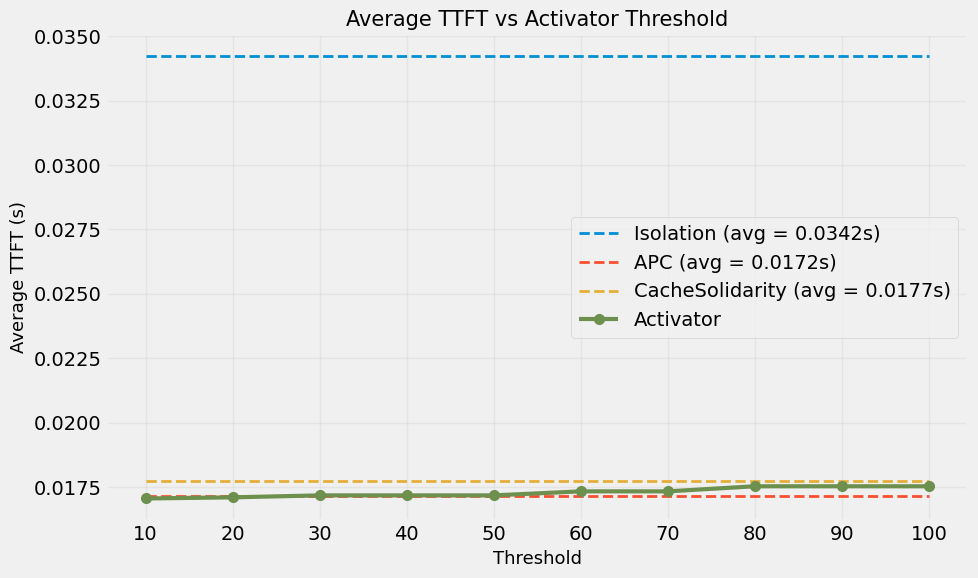


Saved hit-rate plot to:
temp_results/fig10_theta_performance/Llama-2-7b-chat-hf/sensitivity/analysis/activator_hit_rate.png


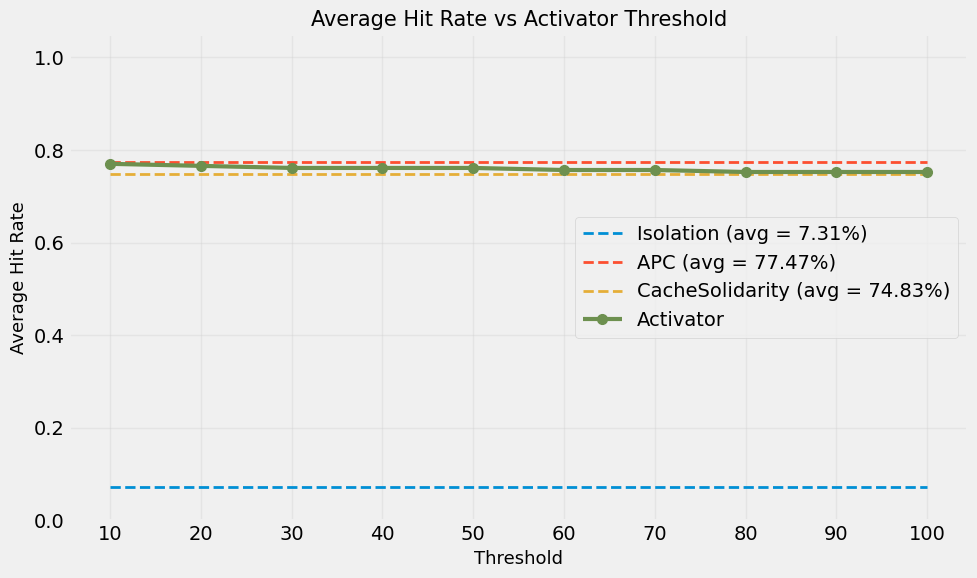



DONE
Analysis directory:
temp_results/fig10_theta_performance/Llama-2-7b-chat-hf/sensitivity/analysis

Per-RPS CSV:
temp_results/fig10_theta_performance/Llama-2-7b-chat-hf/sensitivity/analysis/per_rps_results.csv

System averages CSV:
temp_results/fig10_theta_performance/Llama-2-7b-chat-hf/sensitivity/analysis/system_averages.csv

Activator CSV:
temp_results/fig10_theta_performance/Llama-2-7b-chat-hf/sensitivity/analysis/activator_results.csv

TTFT plot:
temp_results/fig10_theta_performance/Llama-2-7b-chat-hf/sensitivity/analysis/activator_ttft.png

Hit-rate plot:
temp_results/fig10_theta_performance/Llama-2-7b-chat-hf/sensitivity/analysis/activator_hit_rate.png


In [13]:
import json
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# Configuration
# ============================================================

BASE_DIR = Path(
    "./temp_results/fig10_theta_performance"
)

MODEL = "Llama-2-7b-chat-hf"
WORKLOAD = "sensitivity"

SYSTEMS = [
    "Isolation",
    "APC",
    "CacheSolidarity",
]

# Activator thresholds
THRESHOLDS = range(10, 101, 10)

# Users to exclude from BOTH TTFT and hit-rate calculations
EXCLUDED_USERS = {
    "victim",
    "attacker 1",
    "attacker 2",
    "attacker 3",
    "attacker 4",
    "attacker 5",
    "attacker 6",
    "attacker 7",
    "attacker 8",
    "attacker 9",
}


# ============================================================
# Paths
# ============================================================

WORKLOAD_DIR = (
    BASE_DIR
    / MODEL
    / WORKLOAD
)


# ============================================================
# User filtering
# ============================================================

def is_excluded_user(user_id):
    """
    Return True if the user should be excluded.

    Explicitly excludes:
        victim
        attacker1 ... attacker9

    Also accepts:
        attacker 1
        attacker 2
        ...
        attacker 9
    """

    if user_id is None:
        return False

    user = str(user_id).strip().lower()

    # Direct exclusion
    if user in EXCLUDED_USERS:
        return True

    # Also support "attacker 1", "attacker 2", etc.
    match = re.fullmatch(
        r"attacker\s*([1-9])",
        user,
    )

    if match:
        return True

    return False


# ============================================================
# Read JSONL
# ============================================================

def read_jsonl(path):

    records = []

    if not path.exists():
        return records

    with open(path, "r") as f:

        for line_number, line in enumerate(
            f,
            start=1,
        ):

            line = line.strip()

            if not line:
                continue

            try:

                records.append(
                    json.loads(line)
                )

            except json.JSONDecodeError as e:

                print(
                    f"WARNING: Could not parse {path}, "
                    f"line {line_number}: {e}"
                )

    return records


# ============================================================
# Calculate average TTFT
# ============================================================

def calculate_average_ttft(workload_file):

    records = read_jsonl(
        workload_file
    )

    ttfts = []

    total_records = 0
    excluded_records = 0

    for record in records:

        total_records += 1

        user_id = record.get(
            "user_id"
        )

        # ----------------------------------------------------
        # Exclude victim and attacker users
        # ----------------------------------------------------

        if is_excluded_user(user_id):

            excluded_records += 1

            continue

        # ----------------------------------------------------
        # Get TTFT
        # ----------------------------------------------------

        ttft = record.get(
            "ttft"
        )

        if ttft is None:
            continue

        try:

            ttft = float(ttft)

        except (TypeError, ValueError):

            print(
                f"WARNING: Invalid TTFT value "
                f"in {workload_file}: {ttft}"
            )

            continue

        # Ignore invalid numerical values
        if not np.isfinite(ttft):
            continue

        ttfts.append(
            ttft
        )

    print(
        f"      TTFT records: "
        f"{total_records:,}"
    )

    print(
        f"      TTFT excluded users: "
        f"{excluded_records:,}"
    )

    print(
        f"      TTFT valid samples: "
        f"{len(ttfts):,}"
    )

    if not ttfts:
        return np.nan

    return np.mean(
        ttfts
    )


# ============================================================
# Calculate hit rate
# ============================================================

def calculate_hit_rate(system_dir):

    block_files = sorted(
        system_dir.glob(
            "block_*.jsonl"
        )
    )

    if not block_files:

        return np.nan

    hit_count = 0
    new_count = 0
    other_events = 0

    excluded_events = 0

    for block_file in block_files:

        records = read_jsonl(
            block_file
        )

        for record in records:

            user_id = record.get(
                "user_id"
            )

            # ------------------------------------------------
            # Exclude victim and attacker users
            # ------------------------------------------------

            if is_excluded_user(user_id):

                excluded_events += 1

                continue

            # ------------------------------------------------
            # Cache event
            # ------------------------------------------------

            event = record.get(
                "event"
            )

            # ------------------------------------------------
            # Hit
            # ------------------------------------------------

            if event == "hit":

                hit_count += 1

            # ------------------------------------------------
            # New block
            # ------------------------------------------------

            elif event == "new":

                new_count += 1

            # ------------------------------------------------
            # Any other event
            # ------------------------------------------------

            else:

                other_events += 1

    # --------------------------------------------------------
    # Hit rate
    #
    # hit rate = hits / (hits + new)
    # --------------------------------------------------------

    total_cache_events = (
        hit_count
        + new_count
    )

    print(
        f"      Hit events: "
        f"{hit_count:,}"
    )

    print(
        f"      New events: "
        f"{new_count:,}"
    )

    print(
        f"      Other events: "
        f"{other_events:,}"
    )

    print(
        f"      Excluded-user events: "
        f"{excluded_events:,}"
    )

    print(
        f"      Valid cache events: "
        f"{total_cache_events:,}"
    )

    if total_cache_events == 0:

        return np.nan

    return (
        hit_count
        / total_cache_events
    )


# ============================================================
# Check directories
# ============================================================

print("=" * 70)
print("CONFIGURATION")
print("=" * 70)

print(
    f"BASE_DIR     = {BASE_DIR}"
)

print(
    f"MODEL        = {MODEL}"
)

print(
    f"WORKLOAD     = {WORKLOAD}"
)

print(
    f"WORKLOAD_DIR = {WORKLOAD_DIR}"
)

print()

print(
    "Excluded users:"
)

for user in sorted(
    EXCLUDED_USERS
):

    print(
        f"  - {user}"
    )

print()


if not BASE_DIR.exists():

    raise FileNotFoundError(
        f"BASE_DIR does not exist:\n"
        f"{BASE_DIR}"
    )


if not WORKLOAD_DIR.exists():

    raise FileNotFoundError(
        f"WORKLOAD_DIR does not exist:\n"
        f"{WORKLOAD_DIR}"
    )


# ============================================================
# Discover RPS directories dynamically
# ============================================================

rate_dirs = []

for path in WORKLOAD_DIR.glob(
    "Rate_*"
):

    if not path.is_dir():
        continue

    rate_string = (
        path.name.removeprefix(
            "Rate_"
        )
    )

    try:

        rps = float(
            rate_string
        )

    except ValueError:

        print(
            f"WARNING: Skipping invalid "
            f"directory: {path}"
        )

        continue

    rate_dirs.append(
        (
            rps,
            path,
        )
    )


# Sort by RPS
rate_dirs.sort(
    key=lambda x: x[0]
)


# ============================================================
# Print discovered RPS values
# ============================================================

print("=" * 70)
print("DISCOVERED RPS VALUES")
print("=" * 70)

if not rate_dirs:

    raise RuntimeError(
        f"No Rate_* directories found in:\n"
        f"{WORKLOAD_DIR}"
    )


for rps, path in rate_dirs:

    print(
        f"RPS = {rps:<6} -> {path}"
    )


# ============================================================
# Calculate metrics
# ============================================================

results = []


print()
print("=" * 70)
print("PROCESSING")
print("=" * 70)


for rps, rate_dir in rate_dirs:

    print()
    print(
        "=" * 70
    )

    print(
        f"PROCESSING RPS = {rps}"
    )

    print(
        "=" * 70
    )

    for system in SYSTEMS:

        system_dir = (
            rate_dir
            / system
        )

        print()
        print(
            f"  System: {system}"
        )

        # ----------------------------------------------------
        # Check system directory
        # ----------------------------------------------------

        if not system_dir.exists():

            print(
                f"    WARNING: missing directory:"
            )

            print(
                f"    {system_dir}"
            )

            results.append({

                "RPS": rps,

                "System": system,

                "TTFT": np.nan,

                "Hit Rate": np.nan,

            })

            continue


        # ====================================================
        # TTFT
        # ====================================================

        workload_file = (
            system_dir
            / f"{WORKLOAD}.jsonl"
        )

        # Support .json as well
        if not workload_file.exists():

            alternative_file = (
                system_dir
                / f"{WORKLOAD}.json"
            )

            if alternative_file.exists():

                workload_file = (
                    alternative_file
                )


        if workload_file.exists():

            print()
            print(
                f"    Workload file:"
            )

            print(
                f"    {workload_file}"
            )

            avg_ttft = (
                calculate_average_ttft(
                    workload_file
                )
            )

        else:

            print()

            print(
                f"    WARNING: no workload "
                f"file found in:"
            )

            print(
                f"    {system_dir}"
            )

            avg_ttft = np.nan


        # ====================================================
        # Hit rate
        # ====================================================

        block_files = sorted(
            system_dir.glob(
                "block_*.jsonl"
            )
        )

        print()

        print(
            f"    Block files found: "
            f"{len(block_files)}"
        )

        hit_rate = (
            calculate_hit_rate(
                system_dir
            )
        )


        # ====================================================
        # Print calculated metrics
        # ====================================================

        print()

        if pd.isna(
            avg_ttft
        ):

            print(
                "    Average TTFT: NaN"
            )

        else:

            print(
                f"    Average TTFT: "
                f"{avg_ttft:.6f} s"
            )


        if pd.isna(
            hit_rate
        ):

            print(
                "    Hit rate: NaN"
            )

        else:

            print(
                f"    Hit rate: "
                f"{hit_rate:.4%}"
            )


        # ====================================================
        # Save
        # ====================================================

        results.append({

            "RPS": rps,

            "System": system,

            "TTFT": avg_ttft,

            "Hit Rate": hit_rate,

        })


# ============================================================
# Per-RPS dataframe
# ============================================================

df = pd.DataFrame(
    results
)


df = df.sort_values(
    [
        "RPS",
        "System",
    ]
).reset_index(
    drop=True
)


# ============================================================
# Print per-RPS results
# ============================================================

print("\n")
print("=" * 70)
print("PER-RPS RESULTS")
print("=" * 70)

print(
    df.to_string(
        index=False
    )
)


# ============================================================
# Output directory
# ============================================================

output_dir = (
    WORKLOAD_DIR
    / "analysis"
)

output_dir.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# Save raw results
# ============================================================

raw_results_file = (
    output_dir
    / "per_rps_results.csv"
)

df.to_csv(
    raw_results_file,
    index=False
)

print()

print(
    f"Saved per-RPS results to:"
)

print(
    raw_results_file
)


# ============================================================
# Average across RPS values
# ============================================================

system_averages = (
    df
    .groupby(
        "System"
    )
    .agg(

        Average_TTFT=(
            "TTFT",
            "mean",
        ),

        Average_Hit_Rate=(
            "Hit Rate",
            "mean",
        ),

    )
    .reset_index()
)


# ============================================================
# Print system averages
# ============================================================

print("\n")
print("=" * 70)
print("AVERAGE OVER ALL RPS VALUES")
print("=" * 70)

print(
    system_averages.to_string(
        index=False
    )
)


# ============================================================
# Save system averages
# ============================================================

system_average_file = (
    output_dir
    / "system_averages.csv"
)

system_averages.to_csv(
    system_average_file,
    index=False
)

print()

print(
    f"Saved system averages to:"
)

print(
    system_average_file
)


# ============================================================
# Pivot tables
# ============================================================

ttft_pivot = df.pivot(
    index="RPS",
    columns="System",
    values="TTFT",
)


hit_pivot = df.pivot(
    index="RPS",
    columns="System",
    values="Hit Rate",
)


# ============================================================
# Print pivot tables
# ============================================================

print("\n")
print("=" * 70)
print("TTFT PIVOT")
print("=" * 70)

print(
    ttft_pivot.to_string()
)


print("\n")
print("=" * 70)
print("HIT RATE PIVOT")
print("=" * 70)

print(
    hit_pivot.to_string()
)


# ============================================================
# RPS values usable by Activator
#
# Activator requires BOTH APC and CacheSolidarity
# to have valid TTFT and hit-rate values.
# ============================================================

activator_rps = []


for rps in sorted(
    ttft_pivot.index
):

    # --------------------------------------------------------
    # Required systems must exist
    # --------------------------------------------------------

    if (
        "APC" not in ttft_pivot.columns
        or
        "CacheSolidarity"
        not in ttft_pivot.columns
    ):

        continue


    # --------------------------------------------------------
    # APC TTFT
    # --------------------------------------------------------

    if pd.isna(
        ttft_pivot.loc[
            rps,
            "APC",
        ]
    ):

        continue


    # --------------------------------------------------------
    # CacheSolidarity TTFT
    # --------------------------------------------------------

    if pd.isna(
        ttft_pivot.loc[
            rps,
            "CacheSolidarity",
        ]
    ):

        continue


    # --------------------------------------------------------
    # APC hit rate
    # --------------------------------------------------------

    if pd.isna(
        hit_pivot.loc[
            rps,
            "APC",
        ]
    ):

        continue


    # --------------------------------------------------------
    # CacheSolidarity hit rate
    # --------------------------------------------------------

    if pd.isna(
        hit_pivot.loc[
            rps,
            "CacheSolidarity",
        ]
    ):

        continue


    activator_rps.append(
        rps
    )


# ============================================================
# Print Activator RPS
# ============================================================

print("\n")
print("=" * 70)
print("RPS VALUES USED BY ACTIVATOR")
print("=" * 70)

print(
    activator_rps
)


if not activator_rps:

    raise RuntimeError(
        "Activator has no usable RPS values. "
        "Both APC and CacheSolidarity need valid "
        "TTFT and hit-rate data."
    )


# ============================================================
# Calculate Activator
# ============================================================

activator_results = []


for threshold in THRESHOLDS:

    selected_ttfts = []

    selected_hit_rates = []

    selections = []


    # ========================================================
    # Select system at every RPS
    # ========================================================

    for rps in activator_rps:

        # ----------------------------------------------------
        # Activator rule
        #
        # threshold > RPS
        #     -> CacheSolidarity
        #
        # threshold <= RPS
        #     -> APC
        # ----------------------------------------------------

        if threshold > rps:

            selected_system = (
                "CacheSolidarity"
            )

        else:

            selected_system = "APC"


        # ----------------------------------------------------
        # TTFT
        # ----------------------------------------------------

        ttft = ttft_pivot.loc[
            rps,
            selected_system,
        ]


        # ----------------------------------------------------
        # Hit rate
        # ----------------------------------------------------

        hit_rate = hit_pivot.loc[
            rps,
            selected_system,
        ]


        # ----------------------------------------------------
        # Save selection
        # ----------------------------------------------------

        selected_ttfts.append(
            ttft
        )

        selected_hit_rates.append(
            hit_rate
        )


        selections.append({

            "RPS": rps,

            "System": selected_system,

            "TTFT": ttft,

            "Hit Rate": hit_rate,

        })


    # ========================================================
    # Average across all usable RPS
    # ========================================================

    activator_avg_ttft = np.mean(
        selected_ttfts
    )


    activator_avg_hit_rate = np.mean(
        selected_hit_rates
    )


    # ========================================================
    # Save Activator result
    # ========================================================

    activator_results.append({

        "Threshold": threshold,

        "Average TTFT":
            activator_avg_ttft,

        "Average Hit Rate":
            activator_avg_hit_rate,

    })


    # ========================================================
    # Print selection details
    # ========================================================

    print()
    print(
        "=" * 70
    )

    print(
        f"THRESHOLD = {threshold}"
    )

    print(
        "=" * 70
    )


    selections_df = pd.DataFrame(
        selections
    )


    print(
        selections_df.to_string(
            index=False
        )
    )


    print()

    print(
        f"Activator average TTFT = "
        f"{activator_avg_ttft:.6f} s"
    )

    print(
        f"Activator average hit rate = "
        f"{activator_avg_hit_rate:.4%}"
    )


# ============================================================
# Activator dataframe
# ============================================================

activator_df = pd.DataFrame(
    activator_results
)


# ============================================================
# Print Activator results
# ============================================================

print("\n")
print("=" * 70)
print("ACTIVATOR RESULTS")
print("=" * 70)

print(
    activator_df.to_string(
        index=False
    )
)


# ============================================================
# Save Activator results
# ============================================================

activator_file = (
    output_dir
    / "activator_results.csv"
)

activator_df.to_csv(
    activator_file,
    index=False
)

print()

print(
    f"Saved Activator results to:"
)

print(
    activator_file
)


# ============================================================
# Get baseline averages
# ============================================================

def get_system_average(
    system,
    metric,
):

    row = system_averages[
        system_averages[
            "System"
        ] == system
    ]

    if row.empty:

        return np.nan

    return row.iloc[0][
        metric
    ]


# ------------------------------------------------------------
# TTFT
# ------------------------------------------------------------

isolation_ttft = (
    get_system_average(
        "Isolation",
        "Average_TTFT",
    )
)


apc_ttft = (
    get_system_average(
        "APC",
        "Average_TTFT",
    )
)


cache_ttft = (
    get_system_average(
        "CacheSolidarity",
        "Average_TTFT",
    )
)


# ------------------------------------------------------------
# Hit rate
# ------------------------------------------------------------

isolation_hit = (
    get_system_average(
        "Isolation",
        "Average_Hit_Rate",
    )
)


apc_hit = (
    get_system_average(
        "APC",
        "Average_Hit_Rate",
    )
)


cache_hit = (
    get_system_average(
        "CacheSolidarity",
        "Average_Hit_Rate",
    )
)


# ============================================================
# Print baseline values
# ============================================================

print("\n")
print("=" * 70)
print("BASELINE AVERAGES")
print("=" * 70)

print(
    f"Isolation TTFT:          "
    f"{isolation_ttft:.6f} s"
)

print(
    f"APC TTFT:                "
    f"{apc_ttft:.6f} s"
)

print(
    f"CacheSolidarity TTFT:    "
    f"{cache_ttft:.6f} s"
)

print()

print(
    f"Isolation hit rate:      "
    f"{isolation_hit:.4%}"
)

print(
    f"APC hit rate:            "
    f"{apc_hit:.4%}"
)

print(
    f"CacheSolidarity hit rate:"
    f" {cache_hit:.4%}"
)


# ============================================================
# PLOT 1: TTFT
# ============================================================

plt.figure(
    figsize=(10, 6)
)


# ------------------------------------------------------------
# Isolation
# ------------------------------------------------------------

plt.plot(

    activator_df["Threshold"],

    [isolation_ttft]
    * len(activator_df),

    linestyle="--",

    linewidth=2,

    label=(
        f"Isolation "
        f"(avg = "
        f"{isolation_ttft:.4f}s)"
    ),
)


# ------------------------------------------------------------
# APC
# ------------------------------------------------------------

plt.plot(

    activator_df["Threshold"],

    [apc_ttft]
    * len(activator_df),

    linestyle="--",

    linewidth=2,

    label=(
        f"APC "
        f"(avg = "
        f"{apc_ttft:.4f}s)"
    ),
)


# ------------------------------------------------------------
# CacheSolidarity
# ------------------------------------------------------------

plt.plot(

    activator_df["Threshold"],

    [cache_ttft]
    * len(activator_df),

    linestyle="--",

    linewidth=2,

    label=(
        f"CacheSolidarity "
        f"(avg = "
        f"{cache_ttft:.4f}s)"
    ),
)


# ------------------------------------------------------------
# Activator
# ------------------------------------------------------------

plt.plot(

    activator_df["Threshold"],

    activator_df[
        "Average TTFT"
    ],

    marker="o",

    linewidth=3,

    markersize=7,

    label="Activator",
)


# ------------------------------------------------------------
# Formatting
# ------------------------------------------------------------

plt.xlabel(
    "Threshold",
    fontsize=13,
)

plt.ylabel(
    "Average TTFT (s)",
    fontsize=13,
)

plt.title(
    "Average TTFT vs Activator Threshold",
    fontsize=15,
)

plt.xticks(
    list(THRESHOLDS)
)

plt.grid(
    True,
    alpha=0.3,
)

plt.legend()

plt.tight_layout()


# ------------------------------------------------------------
# Save figure
# ------------------------------------------------------------

ttft_plot_file = (
    output_dir
    / "activator_ttft.png"
)

plt.savefig(
    ttft_plot_file,
    dpi=300,
    bbox_inches="tight",
)

print()

print(
    f"Saved TTFT plot to:"
)

print(
    ttft_plot_file
)

plt.show()


# ============================================================
# PLOT 2: HIT RATE
# ============================================================

plt.figure(
    figsize=(10, 6)
)


# ------------------------------------------------------------
# Isolation
# ------------------------------------------------------------

plt.plot(

    activator_df["Threshold"],

    [isolation_hit]
    * len(activator_df),

    linestyle="--",

    linewidth=2,

    label=(
        f"Isolation "
        f"(avg = "
        f"{isolation_hit:.2%})"
    ),
)


# ------------------------------------------------------------
# APC
# ------------------------------------------------------------

plt.plot(

    activator_df["Threshold"],

    [apc_hit]
    * len(activator_df),

    linestyle="--",

    linewidth=2,

    label=(
        f"APC "
        f"(avg = "
        f"{apc_hit:.2%})"
    ),
)


# ------------------------------------------------------------
# CacheSolidarity
# ------------------------------------------------------------

plt.plot(

    activator_df["Threshold"],

    [cache_hit]
    * len(activator_df),

    linestyle="--",

    linewidth=2,

    label=(
        f"CacheSolidarity "
        f"(avg = "
        f"{cache_hit:.2%})"
    ),
)


# ------------------------------------------------------------
# Activator
# ------------------------------------------------------------

plt.plot(

    activator_df["Threshold"],

    activator_df[
        "Average Hit Rate"
    ],

    marker="o",

    linewidth=3,

    markersize=7,

    label="Activator",
)


# ------------------------------------------------------------
# Formatting
# ------------------------------------------------------------

plt.xlabel(
    "Threshold",
    fontsize=13,
)

plt.ylabel(
    "Average Hit Rate",
    fontsize=13,
)

plt.title(
    "Average Hit Rate vs Activator Threshold",
    fontsize=15,
)

plt.xticks(
    list(THRESHOLDS)
)

plt.ylim(
    0,
    1.05,
)

plt.grid(
    True,
    alpha=0.3,
)

plt.legend()

plt.tight_layout()


# ------------------------------------------------------------
# Save figure
# ------------------------------------------------------------

hit_rate_plot_file = (
    output_dir
    / "activator_hit_rate.png"
)

plt.savefig(
    hit_rate_plot_file,
    dpi=300,
    bbox_inches="tight",
)

print()

print(
    f"Saved hit-rate plot to:"
)

print(
    hit_rate_plot_file
)

plt.show()


# ============================================================
# Final summary
# ============================================================

print("\n")
print("=" * 70)
print("DONE")
print("=" * 70)

print(
    f"Analysis directory:\n"
    f"{output_dir}"
)

print()

print(
    f"Per-RPS CSV:\n"
    f"{raw_results_file}"
)

print()

print(
    f"System averages CSV:\n"
    f"{system_average_file}"
)

print()

print(
    f"Activator CSV:\n"
    f"{activator_file}"
)

print()

print(
    f"TTFT plot:\n"
    f"{ttft_plot_file}"
)

print()

print(
    f"Hit-rate plot:\n"
    f"{hit_rate_plot_file}"
)

Found 6 RPS directories.
Target attacker: attacker 2
Success condition: target attacker has the smallest TTFT
False-positive systems: Isolation, CacheSolidarity
False positive condition: attack success rate > 0

RPS = 1.0
----------------------------------------------------------------------------------------------------
Isolation: 0/1 successful (0.00%)
APC: 1/1 successful (100.00%)
CacheSolidarity: 0/1 successful (0.00%)

RPS = 10.0
----------------------------------------------------------------------------------------------------
Isolation: 0/1 successful (0.00%)
APC: 1/1 successful (100.00%)
CacheSolidarity: 0/1 successful (0.00%)

RPS = 25.0
----------------------------------------------------------------------------------------------------
Isolation: 0/1 successful (0.00%)
APC: 1/1 successful (100.00%)
CacheSolidarity: 0/1 successful (0.00%)

RPS = 50.0
----------------------------------------------------------------------------------------------------
Isolation: 0/1 successful 

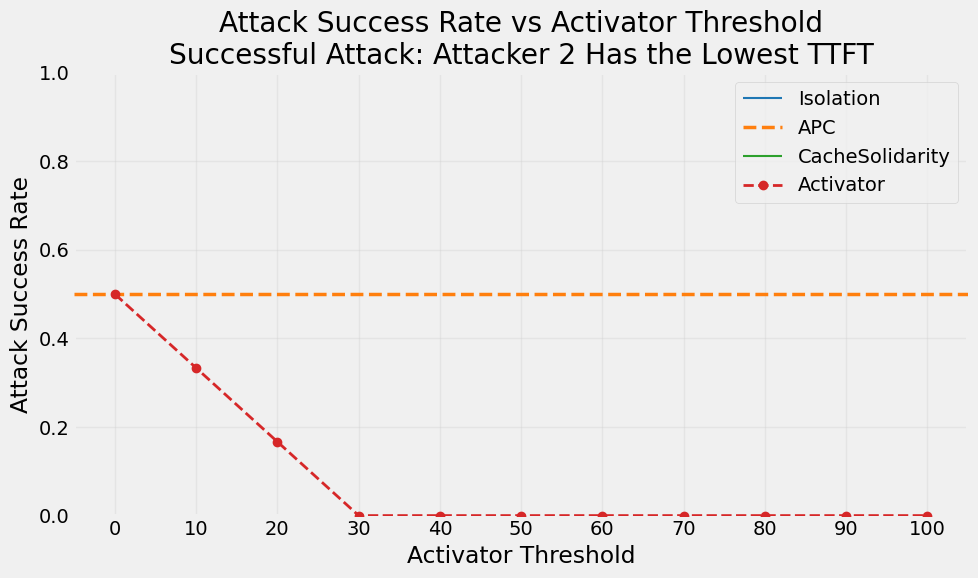


Analysis complete.

Per-RPS results:
temp_results/fig10_theta_performance/Llama-2-7b-chat-hf/sensitivity/security_analysis/security_results.csv

Overall baseline results:
temp_results/fig10_theta_performance/Llama-2-7b-chat-hf/sensitivity/security_analysis/overall_system_security_results.csv

Activator results:
temp_results/fig10_theta_performance/Llama-2-7b-chat-hf/sensitivity/security_analysis/activator_security_results.csv

Plot:
temp_results/fig10_theta_performance/Llama-2-7b-chat-hf/sensitivity/security_analysis/attack_success_rate.png


In [14]:
from pathlib import Path
import json
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# Configuration
# ============================================================

BASE_DIR = Path(
    "./temp_results/fig10_theta_performance"
)

MODEL = "Llama-2-7b-chat-hf"
WORKLOAD = "sensitivity"

SYSTEMS = [
    "Isolation",
    "APC",
    "CacheSolidarity",
]

THRESHOLDS = range(0, 101, 10)

WORKLOAD_DIR = BASE_DIR / MODEL / WORKLOAD

SECURITY_DIR = WORKLOAD_DIR / "security_analysis"

SECURITY_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# Attacker configuration
# ============================================================

ATTACKERS = [
    "attacker 1",
    "attacker 2",
    "attacker 3",
    "attacker 4",
    "attacker 5",
    "attacker 6",
    "attacker 7",
    "attacker 8",
    "attacker 9",
]


# ------------------------------------------------------------
# An attack is successful when ATTACKER 2 has the smallest
# TTFT among all nine attackers.
# ------------------------------------------------------------

TARGET_ATTACKER = "attacker 2"


# ============================================================
# False-positive configuration
# ============================================================

# For these systems, any non-zero attack success rate is
# considered a false positive.
FALSE_POSITIVE_SYSTEMS = [
    "Isolation",
    "CacheSolidarity",
]

FALSE_POSITIVE_THRESHOLD = 0.0


# ============================================================
# Plot color configuration
# ============================================================
#
# Explicit, fixed colors so every system keeps one consistent
# color across its baseline line AND its false-positive
# markers, and the Activator gets its own distinct color.
# This avoids relying on matplotlib's default color cycler,
# which would assign colors based on call order and could
# make a system's line and its own false-positive markers
# end up in different colors.
# ============================================================

SYSTEM_COLORS = {
    "Isolation": "tab:blue",
    "APC": "tab:orange",
    "CacheSolidarity": "tab:green",
}

ACTIVATOR_COLOR = "tab:red"


# ============================================================
# Helpers
# ============================================================

def read_jsonl(path):
    """
    Read a JSONL file.
    """

    records = []

    with open(path, "r", encoding="utf-8") as f:

        for line_number, line in enumerate(
            f,
            start=1
        ):

            line = line.strip()

            if not line:
                continue

            try:
                record = json.loads(line)

            except json.JSONDecodeError:

                print(
                    f"Warning: invalid JSON in {path}, "
                    f"line {line_number}"
                )

                continue

            records.append(record)

    return records


def get_attacker_name(record_id):
    """
    Extract attacker identity from the beginning of the ID.

    Examples:

        attacker 1_1789722605376_9232
        attacker 2_1789722605669_7369

    become:

        attacker 1
        attacker 2
    """

    if record_id is None:
        return None

    record_id = str(
        record_id
    ).strip()

    match = re.match(
        r"^(attacker\s*[1-9])_",
        record_id,
        flags=re.IGNORECASE
    )

    if match is None:
        return None

    attacker = match.group(1).lower()

    # Normalize multiple spaces
    attacker = re.sub(
        r"\s+",
        " ",
        attacker
    )

    return attacker


def find_sensitivity_file(system_dir):
    """
    Find the sensitivity workload file.
    """

    jsonl_file = (
        system_dir / "sensitivity.jsonl"
    )

    if jsonl_file.exists():
        return jsonl_file

    json_file = (
        system_dir / "sensitivity.json"
    )

    if json_file.exists():
        return json_file

    return None


def extract_attacker_records(workload_file):
    """
    Extract attacker records from one sensitivity file.

    Records are separated by attacker and sorted by
    arrival_time.
    """

    records = read_jsonl(
        workload_file
    )

    attacker_records = {
        attacker: []
        for attacker in ATTACKERS
    }

    for record in records:

        record_id = record.get(
            "id"
        )

        attacker = get_attacker_name(
            record_id
        )

        if attacker not in attacker_records:
            continue

        ttft = record.get(
            "ttft"
        )

        if ttft is None:
            continue

        try:

            ttft = float(
                ttft
            )

        except (
            TypeError,
            ValueError
        ):

            continue

        if not np.isfinite(
            ttft
        ):
            continue

        arrival_time = record.get(
            "arrival_time"
        )

        try:

            arrival_time = float(
                arrival_time
            )

        except (
            TypeError,
            ValueError
        ):

            arrival_time = np.inf

        attacker_records[
            attacker
        ].append({
            "id": record_id,
            "ttft": ttft,
            "arrival_time": arrival_time,
        })

    # --------------------------------------------------------
    # Sort each attacker chronologically.
    # --------------------------------------------------------

    for attacker in ATTACKERS:

        attacker_records[
            attacker
        ].sort(
            key=lambda x: x["arrival_time"]
        )

    return attacker_records


# ============================================================
# Calculate attack success
# ============================================================

def calculate_attack_success_rate(
    workload_file
):
    """
    Calculate attack success rate for one sensitivity file.

    Attack #1:
        1st request of attacker 1
        vs
        1st request of attackers 2-9

    Attack #2:
        2nd request of attacker 1
        vs
        2nd request of attackers 2-9

    etc.

    An attack is successful iff ATTACKER 2 has a strictly
    lower TTFT than every other attacker.

    Ties are NOT successful.
    """

    attacker_records = (
        extract_attacker_records(
            workload_file
        )
    )

    counts = {
        attacker: len(
            attacker_records[attacker]
        )
        for attacker in ATTACKERS
    }

    # --------------------------------------------------------
    # Only attacks for which every attacker has a request
    # can be evaluated.
    # --------------------------------------------------------

    complete_attacks = min(
        counts.values()
    )

    max_attacks = max(
        counts.values()
    )

    incomplete_attacks = (
        max_attacks
        - complete_attacks
    )

    successful_attacks = 0

    attack_results = []

    # --------------------------------------------------------
    # Evaluate attacks by sequence number
    # --------------------------------------------------------

    for attack_number in range(
        complete_attacks
    ):

        attacker_ttfts = {}

        attacker_ids = {}

        for attacker in ATTACKERS:

            record = attacker_records[
                attacker
            ][attack_number]

            attacker_ttfts[
                attacker
            ] = record["ttft"]

            attacker_ids[
                attacker
            ] = record["id"]

        # ----------------------------------------------------
        # ATTACK SUCCESS CONDITION
        #
        # Attacker 2 must have the smallest TTFT.
        # ----------------------------------------------------

        target_ttft = attacker_ttfts[
            TARGET_ATTACKER
        ]

        successful = True

        for attacker in ATTACKERS:

            if attacker == TARGET_ATTACKER:
                continue

            if (
                target_ttft
                >= attacker_ttfts[
                    attacker
                ]
            ):

                successful = False

                break

        if successful:

            successful_attacks += 1

        # ----------------------------------------------------
        # Store detailed information
        # ----------------------------------------------------

        result = {
            "attack_number": (
                attack_number + 1
            ),
            "successful": successful,
        }

        for attacker in ATTACKERS:

            result[
                f"{attacker}_id"
            ] = attacker_ids[
                attacker
            ]

            result[
                f"{attacker}_TTFT"
            ] = attacker_ttfts[
                attacker
            ]

        attack_results.append(
            result
        )

    # --------------------------------------------------------
    # Success rate
    # --------------------------------------------------------

    if complete_attacks == 0:

        success_rate = np.nan

    else:

        success_rate = (
            successful_attacks
            / complete_attacks
        )

    details_df = pd.DataFrame(
        attack_results
    )

    return {
        "attack_success_rate": (
            success_rate
        ),
        "successful_attacks": (
            successful_attacks
        ),
        "valid_attacks": (
            complete_attacks
        ),
        "incomplete_attacks": (
            incomplete_attacks
        ),
        "attacker_counts": (
            counts
        ),
        "details": (
            details_df
        ),
    }


# ============================================================
# Find RPS directories
# ============================================================

def get_rps_directories():

    directories = []

    for path in WORKLOAD_DIR.glob(
        "Rate_*"
    ):

        if not path.is_dir():
            continue

        try:

            rps = float(
                path.name.replace(
                    "Rate_",
                    ""
                )
            )

        except ValueError:

            continue

        directories.append(
            (
                rps,
                path
            )
        )

    directories.sort(
        key=lambda x: x[0]
    )

    return directories


# ============================================================
# Main security analysis
# ============================================================

all_results = []

rps_directories = (
    get_rps_directories()
)

print(
    f"Found {len(rps_directories)} "
    f"RPS directories."
)

print("=" * 100)

print(
    f"Target attacker: {TARGET_ATTACKER}"
)

print(
    "Success condition: target attacker has "
    "the smallest TTFT"
)

print(
    "False-positive systems: "
    f"{', '.join(FALSE_POSITIVE_SYSTEMS)}"
)

print(
    "False positive condition: "
    "attack success rate > 0"
)

print("=" * 100)


for rps, rate_dir in rps_directories:

    print()

    print(
        f"RPS = {rps}"
    )

    print(
        "-" * 100
    )

    for system in SYSTEMS:

        system_dir = (
            rate_dir / system
        )

        workload_file = (
            find_sensitivity_file(
                system_dir
            )
        )

        # ----------------------------------------------------
        # Missing sensitivity file
        # ----------------------------------------------------

        if workload_file is None:

            print(
                f"{system}: "
                f"sensitivity file not found"
            )

            all_results.append({
                "RPS": rps,
                "System": system,
                "Attack Success Rate": np.nan,
                "Successful Attacks": 0,
                "Valid Attacks": 0,
                "Incomplete Attacks": 0,
                "False Positive": False,
            })

            continue

        # ----------------------------------------------------
        # Calculate security
        # ----------------------------------------------------

        result = (
            calculate_attack_success_rate(
                workload_file
            )
        )

        # ----------------------------------------------------
        # Save detailed attack results
        # ----------------------------------------------------

        details_df = result[
            "details"
        ]

        if not details_df.empty:

            details_file = (
                system_dir
                / "security_attack_details.csv"
            )

            details_df.to_csv(
                details_file,
                index=False
            )

        # ----------------------------------------------------
        # Summary
        # ----------------------------------------------------

        success_rate = result[
            "attack_success_rate"
        ]

        successful_attacks = result[
            "successful_attacks"
        ]

        valid_attacks = result[
            "valid_attacks"
        ]

        incomplete_attacks = result[
            "incomplete_attacks"
        ]

        # ----------------------------------------------------
        # False-positive detection
        #
        # IMPORTANT:
        #
        # We DO NOT change success_rate here.
        #
        # The original measured result is preserved.
        # ----------------------------------------------------

        false_positive = (
            system in FALSE_POSITIVE_SYSTEMS
            and not pd.isna(
                success_rate
            )
            and success_rate
            > FALSE_POSITIVE_THRESHOLD
        )

        # ----------------------------------------------------
        # Save result
        # ----------------------------------------------------

        all_results.append({
            "RPS": rps,
            "System": system,
            "Attack Success Rate": (
                success_rate
            ),
            "Successful Attacks": (
                successful_attacks
            ),
            "Valid Attacks": (
                valid_attacks
            ),
            "Incomplete Attacks": (
                incomplete_attacks
            ),
            "False Positive": (
                false_positive
            ),
        })

        # ----------------------------------------------------
        # Console output
        # ----------------------------------------------------

        if pd.isna(
            success_rate
        ):

            print(
                f"{system}: "
                f"no complete attacks"
            )

        elif false_positive:

            print(
                f"{system}: "
                f"{successful_attacks}/"
                f"{valid_attacks} "
                f"successful "
                f"({success_rate:.2%}) "
                f"*** FALSE POSITIVE ***"
            )

        else:

            print(
                f"{system}: "
                f"{successful_attacks}/"
                f"{valid_attacks} "
                f"successful "
                f"({success_rate:.2%})"
            )


# ============================================================
# Results DataFrame
# ============================================================

results_df = pd.DataFrame(
    all_results
)

results_df = results_df.sort_values(
    [
        "RPS",
        "System"
    ]
)

results_file = (
    SECURITY_DIR
    / "security_results.csv"
)

results_df.to_csv(
    results_file,
    index=False
)

print()
print("=" * 100)

print(
    "Per-RPS security results saved to:"
)

print(
    results_file
)


# ============================================================
# Overall baseline security
# ============================================================
#
# IMPORTANT:
#
# Isolation, APC, and CacheSolidarity are continuous
# systems.
#
# Their security rate must NOT depend on Activator threshold.
#
# Therefore:
#
#     total successful attacks
#     ------------------------
#         total valid attacks
#
# across ALL RPS/files.
#
# We do NOT average the individual RPS percentages.
# ============================================================

baseline_results = []

for system in SYSTEMS:

    system_data = results_df[
        results_df["System"] == system
    ]

    total_successful_attacks = int(
        system_data[
            "Successful Attacks"
        ].sum()
    )

    total_valid_attacks = int(
        system_data[
            "Valid Attacks"
        ].sum()
    )

    if total_valid_attacks > 0:

        attack_success_rate = (
            total_successful_attacks
            / total_valid_attacks
        )

    else:

        attack_success_rate = np.nan

    baseline_results.append({
        "System": system,
        "Successful Attacks": (
            total_successful_attacks
        ),
        "Valid Attacks": (
            total_valid_attacks
        ),
        "Attack Success Rate": (
            attack_success_rate
        ),
    })


baseline_security_df = pd.DataFrame(
    baseline_results
)

baseline_security_file = (
    SECURITY_DIR
    / "overall_system_security_results.csv"
)

baseline_security_df.to_csv(
    baseline_security_file,
    index=False
)

print()
print("=" * 100)

print(
    "Overall baseline security results:"
)

print()

for _, row in (
    baseline_security_df.iterrows()
):

    if pd.isna(
        row["Attack Success Rate"]
    ):

        print(
            f"{row['System']}: "
            f"no valid attacks"
        )

    else:

        print(
            f"{row['System']}: "
            f"{int(row['Successful Attacks'])}/"
            f"{int(row['Valid Attacks'])} "
            f"successful "
            f"({row['Attack Success Rate']:.2%})"
        )

print()

print(
    "Saved to:"
)

print(
    baseline_security_file
)

print("=" * 100)



activator_results = []

available_rps = sorted(
    results_df[
        "RPS"
    ]
    .dropna()
    .unique()
)


for threshold in THRESHOLDS:

    selected_rates = []

    selected_systems = []

    selected_rps = []

    for rps in available_rps:

        # ----------------------------------------------------
        # Activator logic
        #
        # threshold <= rps:
        #     Isolation
        #
        # otherwise:
        #     APC
        # ----------------------------------------------------

        if threshold > rps:

            selected_system = (
                "Isolation"
            )

        else:

            selected_system = (
                "APC"
            )

        # ----------------------------------------------------
        # Find selected system at this RPS
        # ----------------------------------------------------

        row = results_df[
            (results_df["RPS"] == rps)
            &
            (
                results_df["System"]
                == selected_system
            )
        ]

        if row.empty:
            continue

        success_rate = row.iloc[0][
            "Attack Success Rate"
        ]

        if pd.isna(
            success_rate
        ):
            continue

        selected_rates.append(
            float(success_rate)
        )

        selected_systems.append(
            selected_system
        )

        selected_rps.append(
            rps
        )

    # --------------------------------------------------------
    # Mean attack success rate of selected systems
    # --------------------------------------------------------

    if selected_rates:

        activator_success_rate = float(
            np.mean(
                selected_rates
            )
        )

    else:

        activator_success_rate = np.nan

    activator_results.append({
        "Activator Threshold": (
            threshold
        ),
        "Attack Success Rate": (
            activator_success_rate
        ),
        "Usable RPS Count": (
            len(selected_rates)
        ),
    })


activator_df = pd.DataFrame(
    activator_results
)

activator_file = (
    SECURITY_DIR
    / "activator_security_results.csv"
)

activator_df.to_csv(
    activator_file,
    index=False
)

print()
print("=" * 100)

print(
    "Activator security results saved to:"
)

print(
    activator_file
)

print("=" * 100)


# ============================================================
# Plot
# ============================================================

plt.figure(
    figsize=(10, 6)
)


# ============================================================
# Baseline systems
# ============================================================
#
# Baseline systems are continuous and therefore have ONE
# overall attack success rate each.
#
# They are plotted as horizontal lines, each in its own
# fixed color from SYSTEM_COLORS.
# ============================================================

for system in SYSTEMS:

    row = baseline_security_df[
        baseline_security_df[
            "System"
        ] == system
    ]

    if row.empty:
        continue

    baseline_rate = row.iloc[0][
        "Attack Success Rate"
    ]

    if pd.isna(
        baseline_rate
    ):
        continue

    color = SYSTEM_COLORS[system]

    # --------------------------------------------------------
    # APC
    #
    # Make APC clearly visible.
    # --------------------------------------------------------

    if system == "APC":

        plt.axhline(
            y=baseline_rate,
            color=color,
            linestyle="--",
            linewidth=2.5,
            label="APC",
            zorder=5,
        )

    else:

        plt.axhline(
            y=baseline_rate,
            color=color,
            linewidth=1.5,
            label=system,
        )


# ============================================================
# False-positive markers
# ============================================================
#
# The original false-positive values remain in the CSV.
#
# The false-positive locations are marked with X at zero on
# the graph, using the SAME color as that system's baseline
# line, to visually tie each marker back to its system.
# ============================================================

for system in FALSE_POSITIVE_SYSTEMS:

    system_data = results_df[
        results_df["System"] == system
    ]

    false_positive_data = (
        system_data[
            system_data["False Positive"]
        ]
    )

    if false_positive_data.empty:
        continue

    plt.scatter(
        false_positive_data["RPS"],
        np.zeros(
            len(
                false_positive_data
            )
        ),
        color=SYSTEM_COLORS[system],
        marker="x",
        s=100,
        linewidths=2.5,
        label=(
            f"{system} False Positive"
        ),
        zorder=10,
    )


# ============================================================
# Activator
# ============================================================

plt.plot(
    activator_df[
        "Activator Threshold"
    ],
    activator_df[
        "Attack Success Rate"
    ],
    color=ACTIVATOR_COLOR,
    marker="o",
    linestyle="--",
    linewidth=2,
    label="Activator",
    zorder=6,
)


# ============================================================
# Labels
# ============================================================

plt.xlabel(
    "Activator Threshold"
)

plt.ylabel(
    "Attack Success Rate"
)

plt.title(
    "Attack Success Rate vs Activator Threshold\n"
    "Successful Attack: Attacker 2 Has the Lowest TTFT"
)

plt.ylim(
    0,
    1
)

plt.xticks(
    list(THRESHOLDS)
)

plt.grid(
    True,
    alpha=0.3
)

plt.legend()

plt.tight_layout()


# ============================================================
# Save plot
# ============================================================

plot_file = (
    SECURITY_DIR
    / "attack_success_rate.png"
)

plt.savefig(
    plot_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# Final output
# ============================================================

print()
print("=" * 100)

print(
    "Analysis complete."
)

print()

print(
    "Per-RPS results:"
)

print(
    results_file
)

print()

print(
    "Overall baseline results:"
)

print(
    baseline_security_file
)

print()

print(
    "Activator results:"
)

print(
    activator_file
)

print()

print(
    "Plot:"
)

print(
    plot_file
)

print("=" * 100)

In [19]:
import pandas as pd
import ast


# ============================================================
# Configuration
# ============================================================

datasets = [
    "Flan_processed",
    "ShareGPT_processed",
    "OASST1_processed",
    "UltraChat_processed"
]

BASE_PATH = "./temp_results/privacy_evaluation/eval_data"

th = 2


# ============================================================
# Print table header
# ============================================================

print(
    f"{'Dataset':<25} | "
    f"{'Prompts':>10} | "
    f"{'Secrets %':>10} | "
    f"{'First Entry':>18}"
)

print("-" * 73)


# ============================================================
# Process datasets
# ============================================================

for dataset in datasets:

    PATH = f"{BASE_PATH}/{dataset}.csv"

    # Read CSV
    df = pd.read_csv(PATH)

    # Total number of prompts
    total_rows = len(df)

    # --------------------------------------------------------
    # Percentage of rows with secrets
    # --------------------------------------------------------

    secrets_count = (df["changed"] == 1).sum()

    secrets_pct = (
        secrets_count / total_rows * 100
        if total_rows > 0
        else 0
    )

    # --------------------------------------------------------
    # Convert PI_position from string to list
    # --------------------------------------------------------

    df["PI_position"] = df["PI_position"].apply(
        ast.literal_eval
    )

    # Take the first PI position
    # None if the list is empty
    df["first_PI"] = df["PI_position"].apply(
        lambda x: x[0] if len(x) > 0 else None
    )

    # --------------------------------------------------------
    # Count first PI positions < threshold
    # --------------------------------------------------------

    count = df["first_PI"].apply(
        lambda x: x is not None and x < th
    ).sum()

    pct = (
        count / total_rows * 100
        if total_rows > 0
        else 0
    )

    # --------------------------------------------------------
    # Print row
    # --------------------------------------------------------

    print(
        f"{dataset:<25} | "
        f"{total_rows:>10} | "
        f"{secrets_pct:>9.2f}% | "
        f"{count:>5}/{total_rows:<5} ({pct:>5.2f}%)"
    )

Dataset                   |    Prompts |  Secrets % |        First Entry
-------------------------------------------------------------------------
Flan_processed            |        100 |     97.00% |     0/100   ( 0.00%)
ShareGPT_processed        |        100 |     85.00% |     0/100   ( 0.00%)
OASST1_processed          |        100 |     67.00% |     0/100   ( 0.00%)
UltraChat_processed       |        100 |     36.00% |     0/100   ( 0.00%)


  Dataset  1st Entry %  1st Try %  CacheSolidarity  SafeKV security
     Flan          0.0   0.000000       100.000000        96.907216
 ShareGPT          0.0   0.000000       100.000000        84.705882
   OASST1          0.0   1.492537        98.507463        80.597015
UltraChat          0.0  19.444444        80.555556        86.111111

Saved metrics table -> ./temp_results/cachesolidarity_vs_safekv.csv
Saved plot -> ./temp_results/cachesolidarity_vs_safekv.png


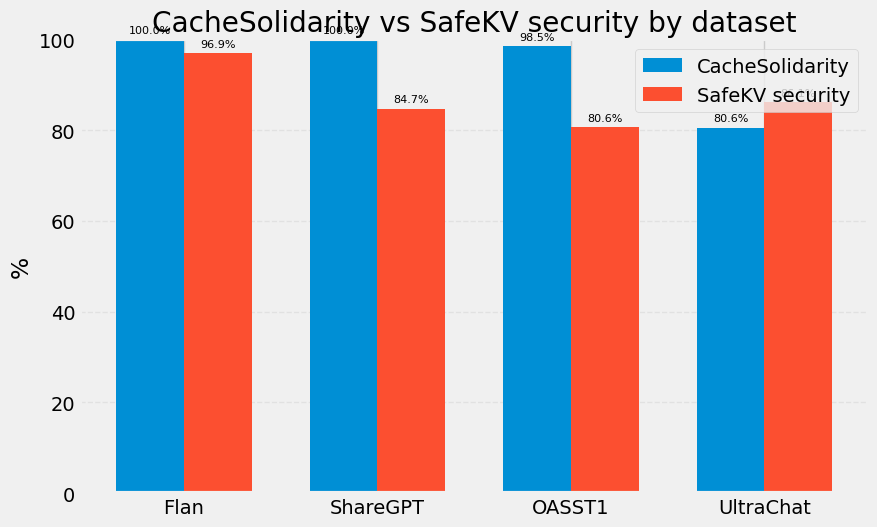

In [15]:
#!/usr/bin/env python3

import ast

import matplotlib.pyplot as plt
import pandas as pd

# ============================================================
# Configuration
# ============================================================

DATASETS = ["Flan_processed", "ShareGPT_processed", "OASST1_processed", "UltraChat_processed"]

EVAL_DATA_DIR = "./temp_results/privacy_evaluation/eval_data"
PII_RESULTS_DIR = "./temp_results/pii_results"

# Count prompts whose first PI position is < TH (same threshold as the summary table script)
TH = 2

OUTPUT_CSV = "./temp_results/cachesolidarity_vs_safekv.csv"
OUTPUT_PLOT = "./temp_results/cachesolidarity_vs_safekv.png"


# ============================================================
# Helper functions (same logic as the eval_data summary script)
# ============================================================

def safe_parse(x):
    """Convert a string representation of a Python list into an actual list."""
    if isinstance(x, str):
        try:
            return ast.literal_eval(x)
        except (ValueError, SyntaxError):
            return x
    return x


def is_fully_recovered(rank_list):
    """Starts with 1 and all items are 1."""
    return (
        isinstance(rank_list, list)
        and len(rank_list) > 0
        and rank_list[0] == 1
        and all(x == 1 for x in rank_list)
    )


def compute_first_entry_pct(dataset: str) -> tuple[float, int]:
    """1st Entry %: prompts whose first PI position is < TH."""
    secrets_path = f"{EVAL_DATA_DIR}/{dataset}.csv"
    df = pd.read_csv(secrets_path)
    total_rows = len(df)

    df["PI_position"] = df["PI_position"].apply(safe_parse)
    df["first_PI"] = df["PI_position"].apply(
        lambda x: x[0] if isinstance(x, list) and len(x) > 0 else None
    )

    count = df["first_PI"].apply(lambda x: x is not None and x < TH).sum()
    pct = count / total_rows * 100 if total_rows > 0 else 0
    return pct, total_rows


def compute_first_try_pct(dataset: str) -> float:
    """1st Try %: rows fully recovered (Match_Rank all == 1, starting with 1)."""
    base_dataset = dataset.rsplit("_", 1)[0]
    match_ranks_path = f"{EVAL_DATA_DIR}/{base_dataset}_processed_match_ranks.csv"
    df_ranks = pd.read_csv(match_ranks_path)

    df_ranks["Match_Rank"] = df_ranks["Match_Rank"].apply(safe_parse)

    total = len(df_ranks)
    full_mask = df_ranks["Match_Rank"].apply(is_fully_recovered)
    full_count = full_mask.sum()

    return full_count / total * 100 if total else 0


def compute_safekv_security(dataset: str) -> float:
    """contains_pii==1 count / changed==1 count * 100."""
    base_dataset = dataset.rsplit("_", 1)[0]
    path = f"{PII_RESULTS_DIR}/{base_dataset}_processed_match_ranks.csv"
    df = pd.read_csv(path)

    changed_count = len(df[df["changed"] == 1])
    if changed_count == 0:
        return 0.0

    contains_pii_count = len(df[df["contains_pii"] == 1])
    return contains_pii_count / changed_count * 100


# ============================================================
# Compute metrics per dataset
# ============================================================

rows = []
for dataset in DATASETS:
    first_entry_pct, total_rows = compute_first_entry_pct(dataset)
    first_try_pct = compute_first_try_pct(dataset)
    cache_solidarity = 100 - (first_entry_pct + first_try_pct)
    safekv_security = compute_safekv_security(dataset)

    rows.append(
        {
            "Dataset": dataset.replace("_processed", ""),
            "1st Entry %": first_entry_pct,
            "1st Try %": first_try_pct,
            "CacheSolidarity": cache_solidarity,
            "SafeKV security": safekv_security,
        }
    )

results = pd.DataFrame(rows)
print(results.to_string(index=False))

results.to_csv(OUTPUT_CSV, index=False)
print(f"\nSaved metrics table -> {OUTPUT_CSV}")


# ============================================================
# Plot: CacheSolidarity vs SafeKV security, grouped by dataset
# ============================================================

fig, ax = plt.subplots(figsize=(9, 5.5))

x = range(len(results))
width = 0.35

ax.bar(
    [i - width / 2 for i in x],
    results["CacheSolidarity"],
    width,
    label="CacheSolidarity",
)
ax.bar(
    [i + width / 2 for i in x],
    results["SafeKV security"],
    width,
    label="SafeKV security",
)

ax.set_ylabel("%")
ax.set_title("CacheSolidarity vs SafeKV security by dataset")
ax.set_xticks(list(x))
ax.set_xticklabels(results["Dataset"])
ax.set_ylim(0, 100)
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.4)

for i, (cs, sk) in enumerate(zip(results["CacheSolidarity"], results["SafeKV security"])):
    ax.text(i - width / 2, cs + 1, f"{cs:.1f}%", ha="center", va="bottom", fontsize=8)
    ax.text(i + width / 2, sk + 1, f"{sk:.1f}%", ha="center", va="bottom", fontsize=8)

fig.tight_layout()
fig.savefig(OUTPUT_PLOT, dpi=150)
print(f"Saved plot -> {OUTPUT_PLOT}")

findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font f

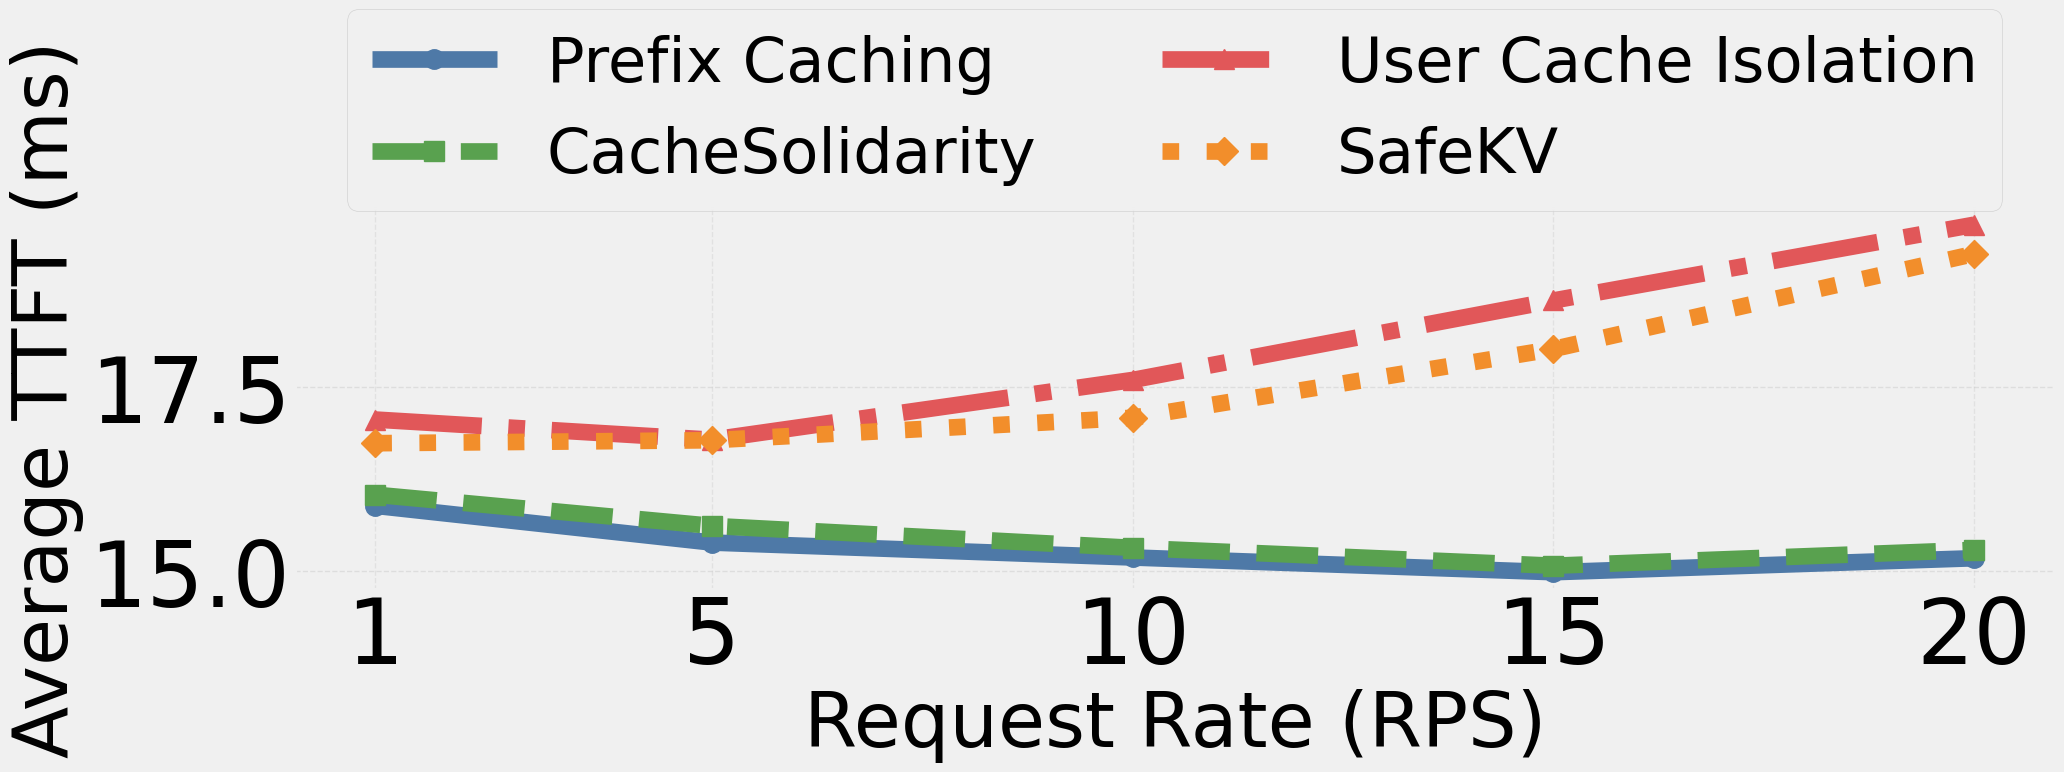

findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font family 'arial' not found.
findfont: Font f

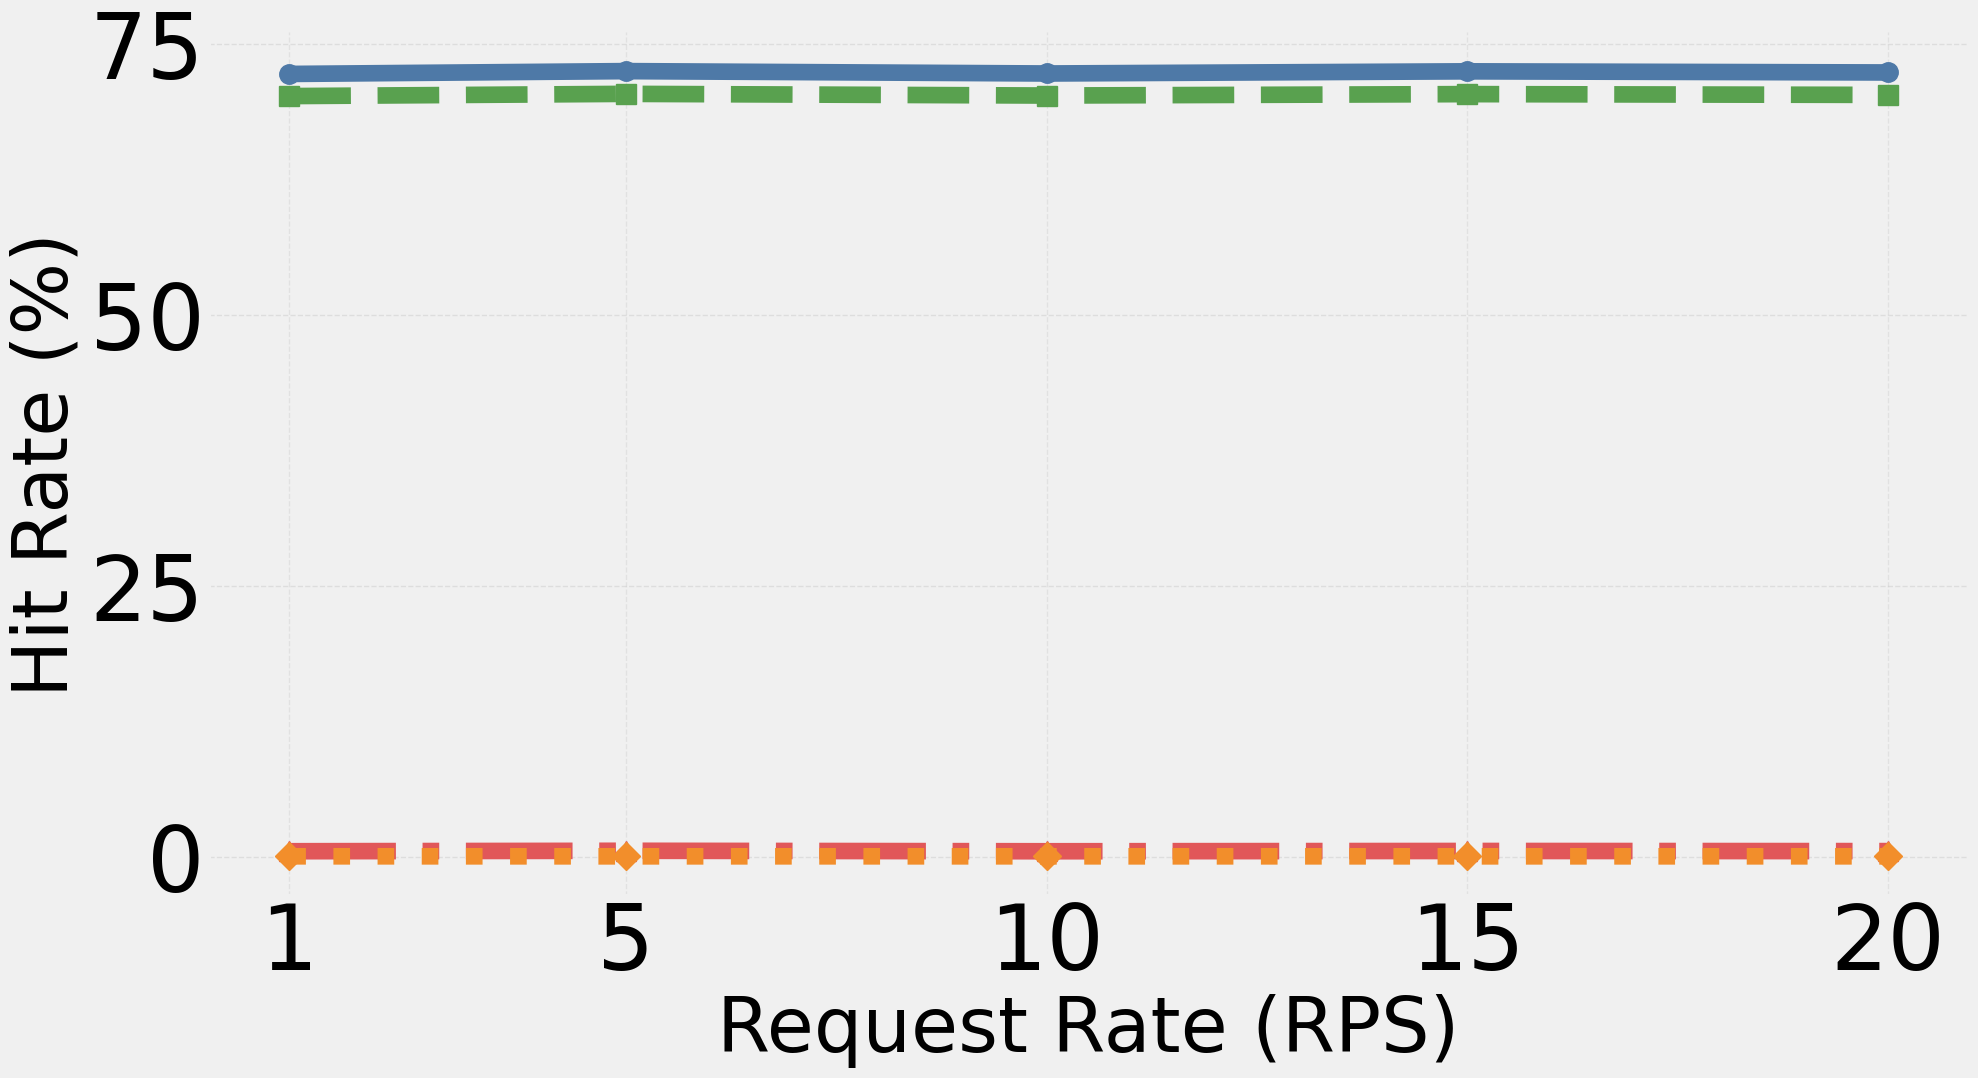


Saved:
  ./plots/ttft_rps.pdf
  ./plots/hit_rate_rps.pdf


In [21]:
import os
import json
import glob
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker


# ── CONFIG ────────────────────────────────────────────────────────────────────

BASE_DIR = (
    "./temp_results/"
    "fig9_RPS/Llama-2-13b-chat-hf/workload_5"
)

SYSTEMS = ["APC", "CacheSolidarity", "Isolation", "SafeKV"]

OUTPUT_DIR = "./plots"
os.makedirs(OUTPUT_DIR, exist_ok=True)

PLOT_CONFIG = {
    "fontsize": 55,
    "labelsize": 55,
    "ticksize": 65,
    "legendsize": 45,
    "figsize": (20, 11),
    "linewidth": 12,
    "markersize": 14,
}

plt.rcParams.update({
    "font.family": "arial",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.linestyle": "--",
    "grid.alpha": 0.4,
})


STYLE = {
    "APC": {"color": "#4E79A7", "marker": "o", "ls": "-"},
    "CacheSolidarity": {"color": "#59A14F", "marker": "s", "ls": "--"},
    "Isolation": {"color": "#E15759", "marker": "^", "ls": "-."},
    "SafeKV": {"color": "#F28E2B", "marker": "D", "ls": ":"},
}


# ── HELPERS ───────────────────────────────────────────────────────────────────

def iter_jsonl(path):
    with open(path, "r") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            try:
                yield json.loads(line)
            except json.JSONDecodeError:
                pass


def compute_avg_ttft(system_dir):
    # Match the per-workload result file (e.g. "workload_5.jsonl"),
    # while explicitly excluding the "block_*.jsonl" hit-rate logs
    # that live in the same directory.
    pattern = os.path.join(system_dir, "*.jsonl")
    files = [
        fp for fp in glob.glob(pattern)
        if not os.path.basename(fp).startswith("block_")
    ]

    if not files:
        return np.nan

    ttfts = []

    for fp in files:
        for obj in iter_jsonl(fp):
            v = obj.get("ttft")
            if v is not None and not np.isnan(float(v)):
                ttfts.append(float(v))

    return np.mean(ttfts) if ttfts else np.nan


def compute_hit_rate(system_dir):
    pattern = os.path.join(system_dir, "block_*.jsonl")
    files = glob.glob(pattern)

    if not files:
        return np.nan

    total, hits = 0, 0

    for fp in files:
        for obj in iter_jsonl(fp):
            event = obj.get("event")
            if event in ("hit", "new"):
                total += 1
                if event == "hit":
                    hits += 1

    return hits / total if total > 0 else np.nan


# ── DATA COLLECTION ───────────────────────────────────────────────────────────

rate_dirs = sorted(
    glob.glob(os.path.join(BASE_DIR, "Rate_*")),
    key=lambda p: float(p.split("Rate_")[1].rstrip("_/"))
)

if not rate_dirs:
    raise SystemExit(f"No Rate_* directories found under {BASE_DIR}")

results = {sys: {} for sys in SYSTEMS}
rps_values = []

for rate_dir in rate_dirs:

    rps = float(os.path.basename(rate_dir).replace("Rate_", "").rstrip("_"))
    rps_values.append(rps)

    for system in SYSTEMS:

        sys_dir = os.path.join(rate_dir, system)

        if os.path.isdir(sys_dir):
            ttft = compute_avg_ttft(sys_dir)
            hr = compute_hit_rate(sys_dir)
        else:
            ttft = np.nan
            hr = np.nan


        results[system][rps] = {
            "ttft": ttft,
            "hit_rate": hr
        }

# ── KEEP ONLY RPS <= 20 ──────────────────────────────────────────────────────

rps_values = sorted(set(rps_values))
rps_values = [r for r in rps_values if r <= 20]

results = {
    system: {r: results[system][r] for r in rps_values if r in results[system]}
    for system in SYSTEMS
}


# ── STYLE HELPERS ─────────────────────────────────────────────────────────────

def style_axes(ax):
    ax.tick_params(axis="both", labelsize=PLOT_CONFIG["ticksize"])
    ax.grid(axis="y", linestyle="--", alpha=0.5)


# ── PLOT 1: TTFT (ms) ─────────────────────────────────────────────────────────

fig, ax1 = plt.subplots(figsize=PLOT_CONFIG["figsize"])

LEGEND_LABELS = {
    "APC": "Prefix Caching",
    "CacheSolidarity": "CacheSolidarity",
    "Isolation": "User Cache Isolation",
    "SafeKV": "SafeKV"
}

for system in SYSTEMS:

    x = rps_values
    y = [
        results[system].get(r, {}).get("ttft", np.nan) * 1000  # seconds -> ms
        for r in x
    ]

    st = STYLE[system]

    ax1.plot(
        x,
        y,
        label=LEGEND_LABELS[system],
        color=st["color"],
        marker=st["marker"],
        linestyle=st["ls"],
        linewidth=PLOT_CONFIG["linewidth"],
        markersize=PLOT_CONFIG["markersize"]
    )

ax1.set_xlabel("Request Rate (RPS)", fontsize=PLOT_CONFIG["labelsize"])
ax1.set_ylabel("Average TTFT (ms)", fontsize=PLOT_CONFIG["labelsize"])

style_axes(ax1)

ax1.legend(
    fontsize=PLOT_CONFIG["legendsize"],
    loc="upper center",
    ncol=2,
    bbox_to_anchor=(0.5, 1.60)
)

ax1.set_xticks(rps_values)

plt.tight_layout()

ttft_path = os.path.join(OUTPUT_DIR, "ttft_rps.pdf")
plt.savefig(ttft_path, bbox_inches="tight", transparent=True)
plt.show()


# ── PLOT 2: HIT RATE ─────────────────────────────────────────────────────────

fig, ax2 = plt.subplots(figsize=PLOT_CONFIG["figsize"])

for system in SYSTEMS:

    x = rps_values
    y = [results[system].get(r, {}).get("hit_rate", np.nan) for r in x]

    st = STYLE[system]

    ax2.plot(
        x,
        y,
        label=LEGEND_LABELS[system],
        color=st["color"],
        marker=st["marker"],
        linestyle=st["ls"],
        linewidth=PLOT_CONFIG["linewidth"],
        markersize=PLOT_CONFIG["markersize"]
    )

ax2.set_xlabel("Request Rate (RPS)", fontsize=PLOT_CONFIG["labelsize"])
ax2.set_ylabel("Hit Rate (%)", fontsize=PLOT_CONFIG["labelsize"])

style_axes(ax2)

# FORCE Y AXIS TICKS
ax2.set_yticks([0, 0.25, 0.5, 0.75])
ax2.set_yticklabels(["0", "25", "50", "75"])

ax2.set_xticks(rps_values)

plt.tight_layout()

hit_path = os.path.join(OUTPUT_DIR, "hit_rate_rps.pdf")
plt.savefig(hit_path, bbox_inches="tight", transparent=True)
plt.show()


print("\nSaved:")
print(" ", ttft_path)
print(" ", hit_path)

[plot1] skip llama3_70b: no file at /home/panagiotis.pennas/Artifact/CacheSolidarity/temp_results/Figure_3_exploitability/llama3_70b/exploitability/Rate_5.0/APC/exploitability.jsonl


/tmp/ipykernel_1100514/943109655.py:88: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  pdf_miss /= np.trapz(pdf_miss, xs)
/tmp/ipykernel_1100514/943109655.py:89: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  pdf_hit /= np.trapz(pdf_hit, xs)
/tmp/ipykernel_1100514/943109655.py:90: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  tv_distance = 0.5 * np.trapz(np.abs(pdf_miss - pdf_hit), xs)
/tmp/ipykernel_1100514/943109655.py:88: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  pdf_miss /= np.trapz(pdf_miss, xs)
/tmp/ipykernel_1100514/943109655.py:89: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the nu

[plot2] skip llama3_70b: no usable rate data


/tmp/ipykernel_1100514/943109655.py:88: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  pdf_miss /= np.trapz(pdf_miss, xs)
/tmp/ipykernel_1100514/943109655.py:89: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  pdf_hit /= np.trapz(pdf_hit, xs)
/tmp/ipykernel_1100514/943109655.py:90: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  tv_distance = 0.5 * np.trapz(np.abs(pdf_miss - pdf_hit), xs)
/tmp/ipykernel_1100514/943109655.py:88: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  pdf_miss /= np.trapz(pdf_miss, xs)
/tmp/ipykernel_1100514/943109655.py:89: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the nu

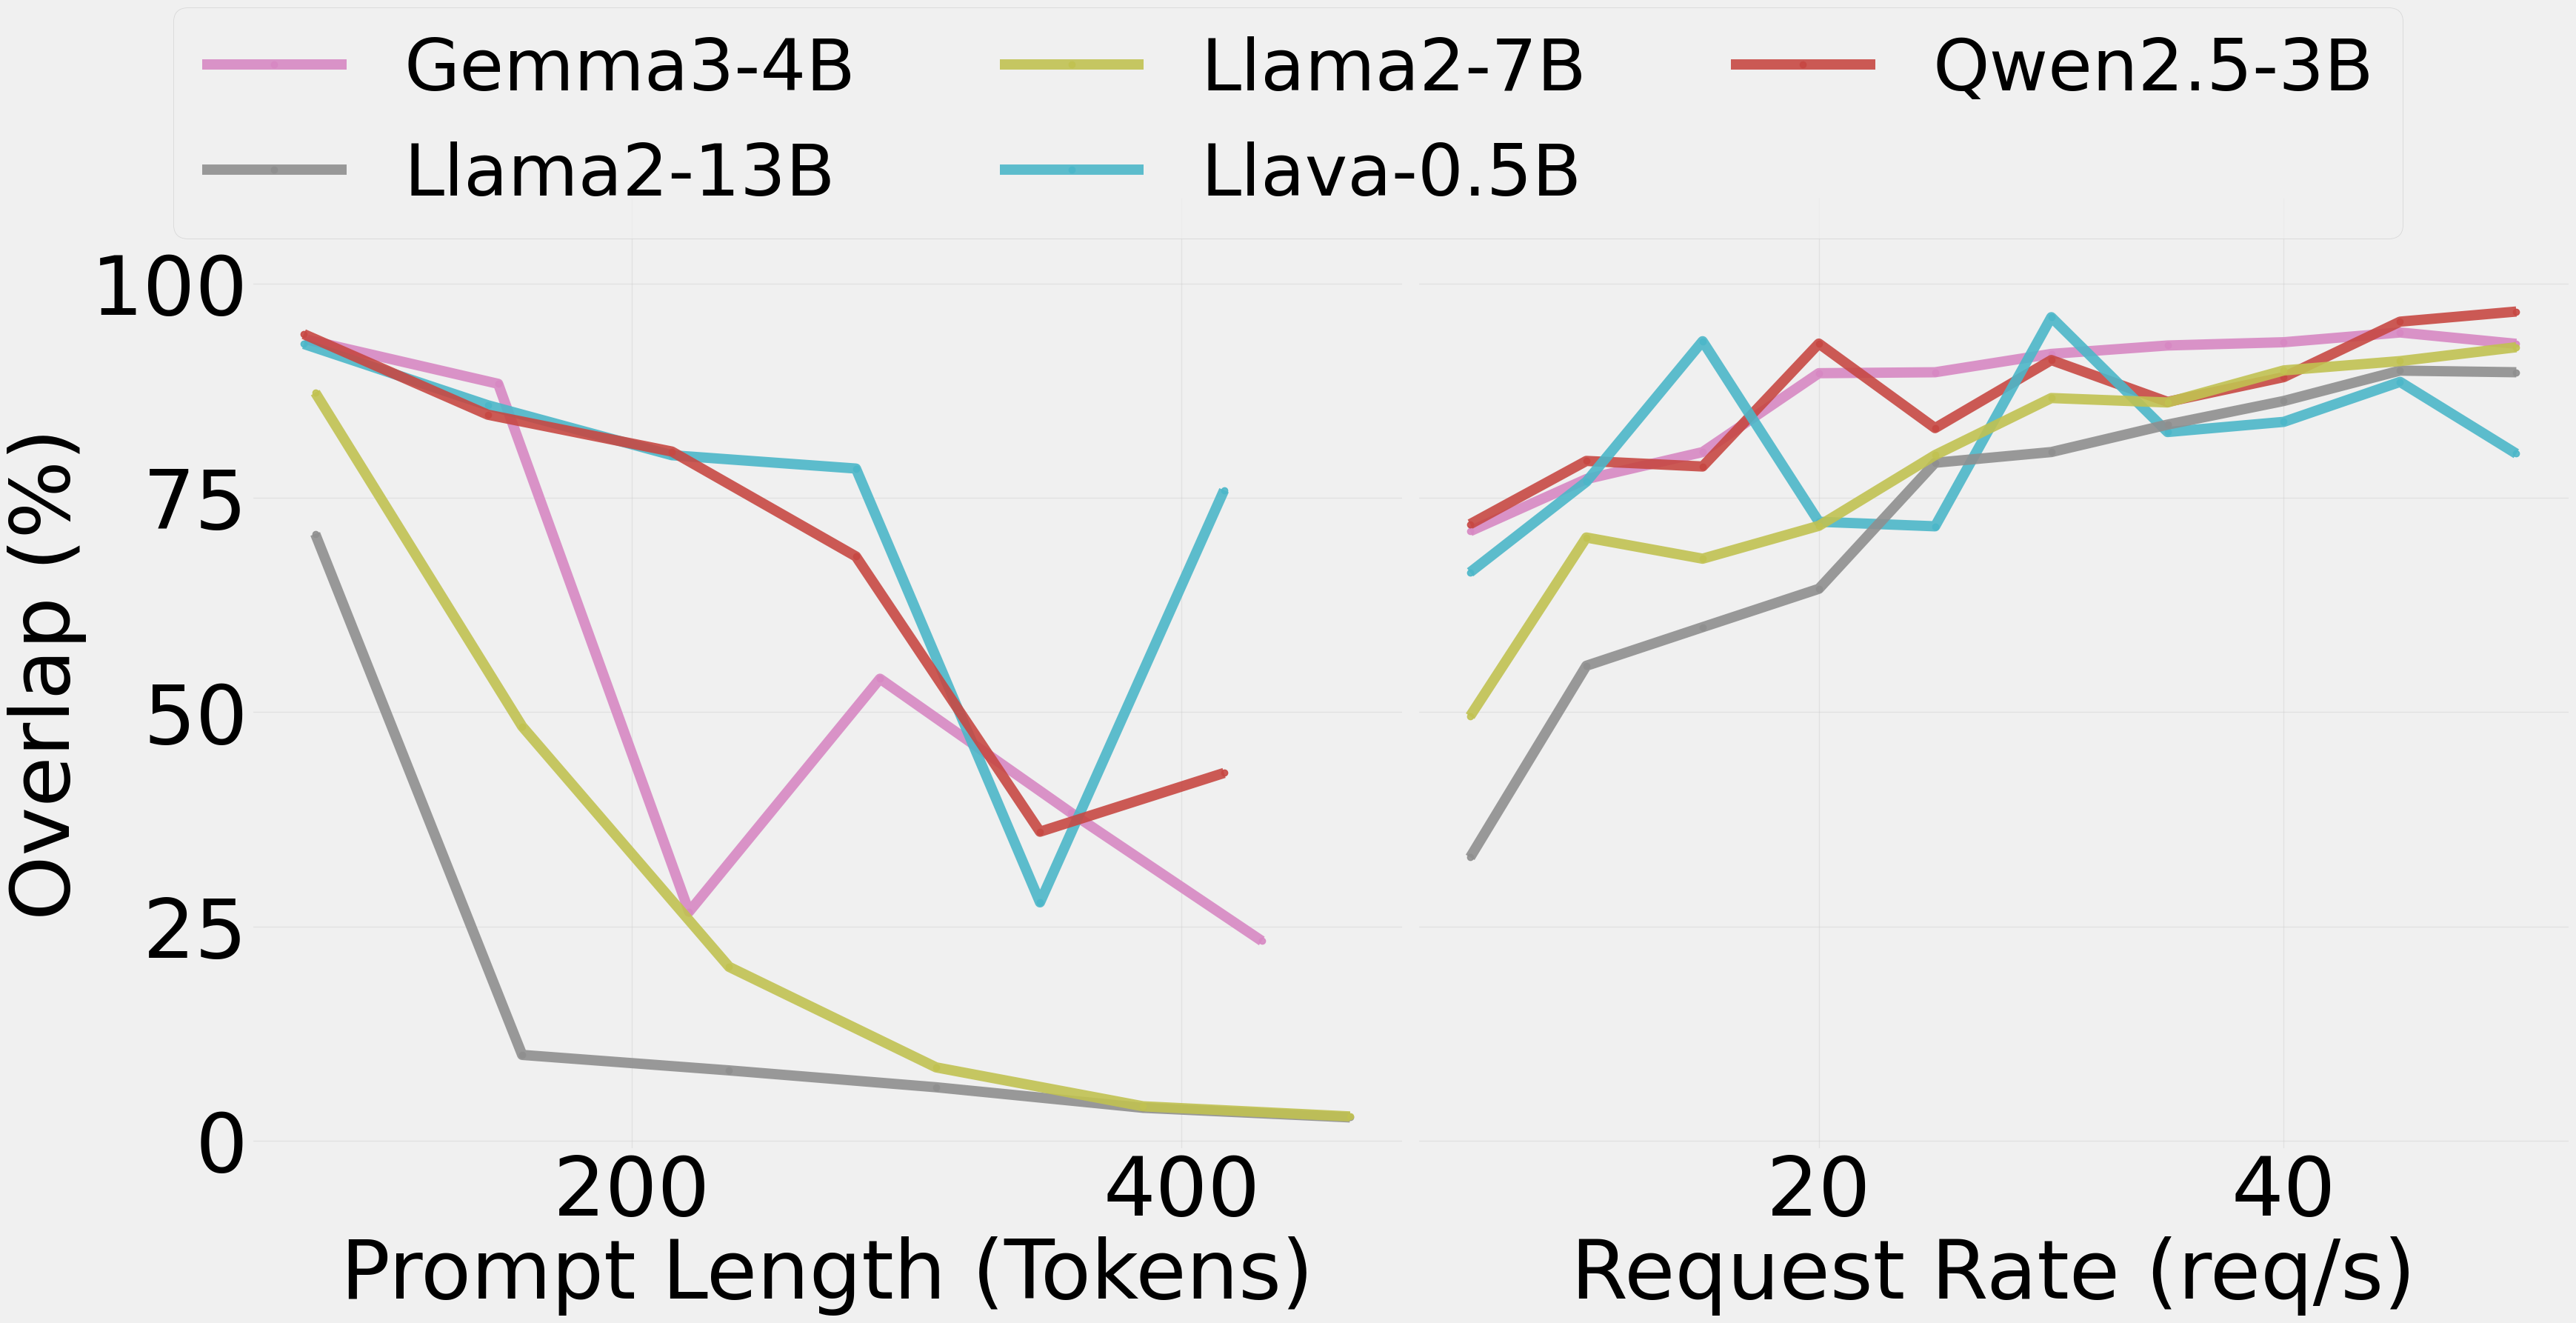

Saved: combined_figure3_overlap_plots.pdf


In [ ]:
import os
import glob
import json
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

# ------------------------------
# Plot & font settings
# ------------------------------
matplotlib.rcParams["pdf.fonttype"] = 42
matplotlib.rcParams["ps.fonttype"] = 42
plt.style.use("fivethirtyeight")

PLOT_CONFIG = {
    "fontsize": 80,
    "labelsize": 80,
    "ticksize": 80,
    "legendsize": 70,
    "figsize": (35, 18),
    "line_width": 15,
}

OUTPUT_PATH = "combined_figure3_overlap_plots.pdf"

# ------------------------------
# Config
# ------------------------------
BASE_DIR = "./temp_results/Figure_3_exploitability"
MODE = "APC"  # the only mode present under Figure_3_exploitability

# Rate used for the "overlap vs prompt length" plot.
# Original script used rate=1, which isn't in this dataset (rates start at 5.0),
# so this defaults to the lowest available rate. Change if you want a different one.
PROMPT_LEN_RATE = 5.0

n_bin = 7
K_TOKENS = 46

# ------------------------------
# Model name mapping / colors
# ------------------------------
model_name_map = {
    "Llama-2-13b-chat-hf": "Llama2-13B",
    "Llama-2-7b-chat-hf": "Llama2-7B",
    "Qwen2-VL-2B-Instruct": "Qwen2-2B",
    "Qwen2-VL-7B-Instruct": "Qwen2-7B",
    "Qwen2.5-VL-3B-Instruct": "Qwen2.5-3B",
    "Qwen2.5-VL-7B-Instruct": "Qwen2.5-7B",
    "gemma-3-4b-it": "Gemma3-4B",
    "llava-onevision-qwen2-0.5b-ov-hf": "Llava-0.5B",
    "llava-onevision-qwen2-7b-ov-chat-hf": "Llava-7B",
    # llama3_70b intentionally excluded: only plotted if real, readable data exists
}

color_map = {
    "Gemma3-4B": "#d788c3",
    "Llama2-13B": "#8f8f8f",
    "Llama2-7B": "#c1c251",
    "Llava-0.5B": "#4cb7c9",
    "Qwen2.5-3B": "#c74843",
    "Qwen2-2B": "#7b6fd0",
    "Qwen2-7B": "#ff9f40",
    "Qwen2.5-7B": "#8c564b",
    "Llava-7B": "#17becf",
    "Llama3-70B": "#2ca02c",
}


# ------------------------------
# Shared helpers
# ------------------------------
def load_jsonl(path):
    with open(path) as f:
        return [json.loads(line) for line in f if line.strip()]


def kde_overlap_pct(miss_vals, hit_vals):
    if len(miss_vals) < 5 or len(hit_vals) < 5:
        return np.nan
    kde_miss = gaussian_kde(miss_vals)
    kde_hit = gaussian_kde(hit_vals)
    xs = np.linspace(0, 65, 500)
    pdf_miss = kde_miss(xs)
    pdf_hit = kde_hit(xs)
    pdf_miss /= np.trapz(pdf_miss, xs)
    pdf_hit /= np.trapz(pdf_hit, xs)
    tv_distance = 0.5 * np.trapz(np.abs(pdf_miss - pdf_hit), xs)
    return (1 - tv_distance) * 100


def prep_occurrence_df(df):
    df = df.copy()
    df["id_prefix"] = df["id"].apply(lambda x: x.split("_")[0])
    df["occurrence"] = df.groupby("id_prefix").cumcount() + 1
    return df


# ------------------------------
# Plot 1 -- Overlap vs Prompt Length (fixed rate)
# ------------------------------
def compute_overlap_vs_prompt(df, model_name):
    if "prompt_tokens_cnt" not in df.columns or "ttft" not in df.columns or "id" not in df.columns:
        return None

    df = df[df["prompt_tokens_cnt"] > K_TOKENS]
    df = prep_occurrence_df(df)
    df = df[df["occurrence"].isin([1, 2])]
    df = df.astype({"prompt_tokens_cnt": float, "ttft": float})
    df = df.dropna(subset=["prompt_tokens_cnt", "ttft"])
    df["ttft"] = df["ttft"] * 1000

    if df.empty:
        return None

    df_miss = df[df["occurrence"] == 1]
    df_hit = df[df["occurrence"] == 2]

    bins = np.linspace(df["prompt_tokens_cnt"].min(), df["prompt_tokens_cnt"].max(), n_bin)
    bin_centers = (bins[:-1] + bins[1:]) / 2
    overlaps = []

    for i in range(len(bins) - 1):
        miss_bin = df_miss[(df_miss["prompt_tokens_cnt"] >= bins[i]) & (df_miss["prompt_tokens_cnt"] < bins[i + 1])]
        hit_bin = df_hit[(df_hit["prompt_tokens_cnt"] >= bins[i]) & (df_hit["prompt_tokens_cnt"] < bins[i + 1])]
        overlaps.append(kde_overlap_pct(miss_bin["ttft"].values, hit_bin["ttft"].values))

    if all(np.isnan(o) for o in overlaps):
        return None

    return pd.DataFrame({
        "model": model_name,
        "prompt_tokens_cnt_bin": bin_centers,
        "overlap_pct_hit": overlaps,
    })


def generate_plot1(ax):
    model_dirs = [d for d in glob.glob(os.path.join(BASE_DIR, "*")) if os.path.isdir(d)]
    results = []

    rate_str = f"{PROMPT_LEN_RATE}"  # e.g. "5.0" -> matches folder "Rate_5.0"

    for model_dir in model_dirs:
        folder_name = os.path.basename(model_dir)
        model_name = model_name_map.get(folder_name, folder_name)

        jsonl_path = os.path.join(
            model_dir, "exploitability", f"Rate_{rate_str}", MODE, "exploitability.jsonl"
        )
        if not os.path.exists(jsonl_path):
            print(f"[plot1] skip {model_name}: no file at {jsonl_path}")
            continue

        data = load_jsonl(jsonl_path)
        if not data:
            print(f"[plot1] skip {model_name}: empty file")
            continue

        res = compute_overlap_vs_prompt(pd.DataFrame(data), model_name)
        if res is None:
            print(f"[plot1] skip {model_name}: not enough usable data")
            continue

        results.append(res)

    if not results:
        print("[plot1] no models had usable data -- leaving subplot empty")
        return

    df_results = pd.concat(results, ignore_index=True)

    for model_name, group in df_results.groupby("model"):
        color = color_map.get(model_name, "gray")
        ax.plot(
            group["prompt_tokens_cnt_bin"], group["overlap_pct_hit"],
            marker="o", linewidth=10, alpha=0.9, label=model_name, color=color,
        )

    ax.set_xlabel("Prompt Length (Tokens)", fontsize=PLOT_CONFIG["labelsize"])
    ax.set_ylabel("Overlap (%)", fontsize=PLOT_CONFIG["labelsize"])
    ax.tick_params(axis="both", labelsize=PLOT_CONFIG["ticksize"])
    ax.grid(True)
    ax.set_ylim(0, 100)
    ax.set_yticks([0, 25, 50, 75, 100])


# ------------------------------
# Plot 2 -- Overlap vs Request Rate
# ------------------------------
def process_jsonl_file(jsonl_path):
    data = load_jsonl(jsonl_path)
    if not data:
        return np.nan
    df = pd.DataFrame(data)
    if df.empty or "id" not in df.columns or "ttft" not in df.columns:
        return np.nan

    df = prep_occurrence_df(df)
    df = df[df["occurrence"].isin([1, 2])]
    df = df.dropna(subset=["ttft"])
    df["ttft"] = df["ttft"].astype(float) * 1000

    df_miss = df[df["occurrence"] == 1]
    df_hit = df[df["occurrence"] == 2]
    return kde_overlap_pct(df_miss["ttft"].values, df_hit["ttft"].values)


def generate_plot2(ax):
    model_dirs = [d for d in glob.glob(os.path.join(BASE_DIR, "*")) if os.path.isdir(d)]

    for model_dir in model_dirs:
        folder_name = os.path.basename(model_dir)
        model_name = model_name_map.get(folder_name, folder_name)

        rate_files = glob.glob(
            os.path.join(model_dir, "exploitability", "Rate_*", MODE, "exploitability.jsonl")
        )

        rate_metrics = []
        for file_path in rate_files:
            rate_part = [p for p in file_path.split(os.sep) if p.startswith("Rate_")]
            if not rate_part:
                continue
            rate = float(rate_part[0].replace("Rate_", "").rstrip("_"))
            overlap = process_jsonl_file(file_path)
            if not np.isnan(overlap):
                rate_metrics.append((rate, overlap))

        if not rate_metrics:
            print(f"[plot2] skip {model_name}: no usable rate data")
            continue

        rate_metrics.sort(key=lambda x: x[0])
        rates, overlaps = zip(*rate_metrics)

        color = color_map.get(model_name, "gray")
        ax.plot(
            rates, overlaps,
            marker="o", linewidth=10, alpha=0.9, label=model_name, color=color,
        )

    ax.set_xlabel("Request Rate (req/s)", fontsize=PLOT_CONFIG["labelsize"])
    ax.set_ylim(-1, 110)
    ax.set_yticks([0, 25, 50, 75, 100])
    ax.tick_params(axis="both", labelsize=PLOT_CONFIG["ticksize"])
    ax.grid(True)


# ------------------------------
# Combine into one PDF with a shared legend
# ------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=PLOT_CONFIG["figsize"], sharey=True)

generate_plot1(ax1)
generate_plot2(ax2)

handles, labels = [], []
for ax in [ax1, ax2]:
    h, l = ax.get_legend_handles_labels()
    handles.extend(h)
    labels.extend(l)

unique = dict(zip(labels, handles))
if unique:
    fig.legend(
        unique.values(), unique.keys(),
        fontsize=PLOT_CONFIG["legendsize"],
        ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.02),
    )

plt.tight_layout()
plt.subplots_adjust(top=0.85)
fig.savefig(OUTPUT_PATH, dpi=300, bbox_inches="tight", format="pdf", transparent=True)
plt.show()

print(f"Saved: {OUTPUT_PATH}")